# 09 — Tìm điểm bắt đầu, kết thúc sóng T và vẽ quỹ đạo 3D

## 1. Notebook này làm gì?

Notebook tìm **hai mốc đầu và cuối của sóng T**, rồi lấy đoạn tín hiệu giữa hai mốc để vẽ trong không gian 3 chiều.

Các khái niệm dùng xuyên suốt:

- **QRS**: phần tín hiệu gắn với lúc các buồng thất được hoạt hoá điện.
- **Sóng T**: phần tín hiệu gắn với quá trình hồi phục điện của các buồng thất. **T-on** là điểm bắt đầu; **T-off** hay **T-end** là điểm kết thúc.
- **XYZ / VCG**: ba thành phần điện tim theo ba hướng không gian. Mỗi thời điểm có một bộ số `(X, Y, Z)`, tương ứng một điểm 3D.
- **T loop**: đường nối các điểm XYZ theo thời gian, từ T-on đến T-off. Đường này không nhất thiết khép kín hoàn toàn.
- **V1**: kết quả của cách tách cũ. **V2**: kết quả của cách Wavelet/TLS đang thử trong notebook này.
- **Wavelet**: phép biến đổi giúp làm rõ tín hiệu thay đổi ở những vị trí nào. **TLS**: cách tìm một đường thẳng đại diện cho một đám điểm 3D, từ đó chọn hướng quan sát. Hai bước này được giải thích ở mục 6 và 10.

**Luồng thực hiện:** lấy nhịp đại diện đã lưu → biến đổi từng trục → kết hợp ba trục → tìm hai mốc T → cắt và vẽ T loop.

Cách làm dựa trên [Martínez 2004](https://doi.org/10.1109/TBME.2003.821031) và [Almeida 2009](https://doi.org/10.1109/TBME.2009.2021658), có điều chỉnh cho dữ liệu của dự án. Chưa có đối chiếu đầu ra với chương trình của tác giả để khẳng định hai bên cho kết quả tương đương. Các công thức và điều chỉnh được ghi trong [tài liệu phương pháp](METHOD_REPRODUCTION.md).

## Chuẩn bị dữ liệu trên máy này
Chạy cell dưới một lần mỗi phiên. Dữ liệu PTB được tải từ GitHub Releases nếu còn thiếu.
Notebook 06–09 tự tạo các đầu vào phụ thuộc còn thiếu; lần đầu có thể chạy lâu.
Hướng dẫn và dung lượng: xem `README.md` và `docs/REPRODUCIBILITY.md`.

Nếu bộ artifact V1 có sẵn nhưng thiếu dấu hoàn tất của báo cáo cũ, bước chuẩn bị chỉ tái sử dụng khi hash **hai module số học**, cấu hình, split, record ID và lưới thời gian median đều hợp lệ. Việc này không đánh dấu báo cáo cũ là đã chạy xong. CSV feature V1 còn thiếu sẽ được tạo từ raw qua notebook 06; lần chạy notebook 09 đầu tiên vì vậy có thể lâu hơn.

In [1]:
from pathlib import Path
import os, sys

NOTEBOOK_ROOT=next((p for p in [Path.cwd(),Path.cwd()/"VCG",*Path.cwd().parents]
                    if (p/"project_setup.py").is_file()),None)
if NOTEBOOK_ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục vcg hoặc vcg/VCG.")
NOTEBOOK_ROOT=NOTEBOOK_ROOT.resolve()
if str(NOTEBOOK_ROOT) not in sys.path: sys.path.insert(0,str(NOTEBOOK_ROOT))
# Các đường dẫn tương đối và unittest bên dưới dùng cùng thư mục project.
os.chdir(NOTEBOOK_ROOT)
from project_setup import prepare_notebook
prepare_notebook(9)

V1: artifact đầu vào đã được xác minh; không resume báo cáo cũ thiếu completion.
Đầu vào Notebook 09 đã sẵn sàng.


## 2. Chuẩn bị các hàm và thông số

**Mục đích:** nạp công cụ cần dùng và đọc kết quả đã có của V1.

Ba nhóm file chính:

- `vcg_t_almeida.py`: thực hiện phép biến đổi và tìm hai mốc T.
- `scripts/run_vcg_t_almeida_experiment.py`: đọc dữ liệu, lưu kết quả từng bản ghi và tổng hợp báo cáo.
- Các file `vcg_t_almeida_plots.py` và `vcg_t_almeida_gallery.py`: vẽ hình trong notebook và giao diện xem từng bản ghi.

Dữ liệu đầu vào là **nhịp đại diện đã lưu**, nằm trong `outputs/vcg_full_evaluation/artifacts/`. Cách tạo nhịp đại diện được giải thích ở mục 4.

**Cách đọc kết quả cell dưới:**

- `CFG` chứa các **thông số cài đặt**, như ngưỡng tìm sóng và số lần lặp tối đa. Đây chưa phải kết quả đo của bệnh nhân.
- `Implementation class` cho biết đây là bản dựng theo bài báo có điều chỉnh.
- `protected files` là số file V1 được theo dõi bằng **mã kiểm tra nội dung** (hash). Nếu nội dung file thay đổi, mã kiểm tra cũng thay đổi.

Các thông số về ngưỡng được giải thích ở mục 7; điều kiện dừng ở mục 13.

In [2]:
from pathlib import Path
from dataclasses import asdict
import os, sys, json, subprocess
os.environ.setdefault('MPLCONFIGDIR', str(__import__('pathlib').Path(__import__('tempfile').gettempdir())/'vcg_t_almeida_mpl'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, IFrame

ROOT = Path.cwd().resolve()
if not (ROOT / 'vcg_t_almeida.py').exists():
    raise RuntimeError('Chạy notebook từ thư mục gốc project')
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / 'scripts'))
from vcg_t_almeida import (AlmeidaConfig, METHOD_CLASS, wavelet_transform,
    build_t_search_window, single_lead_initialization, select_multilead_scale,
    tls_direction, iterate_tls_boundary, project_wavelets, delineate_t, validate_t_bounds)
from vcg_pipeline import FEATURE_NAMES, cut_loop
from run_vcg_t_almeida_experiment import (initialize, process_one, run_experiment,
    verify_v1, DEFAULT_OUT, ARTIFACT_INPUT, safe_id, write_json)
from vcg_reference_metrics import load_median
from vcg_t_almeida_plots import (plot_median, plot_wavelets, plot_single_leads,
    plot_wt_loop, plot_tls_fit, plot_derived, plot_iterations, plot_t_loops)

# The batch renderer uses Agg; register the notebook PNG formatter AFTER
# importing it so display(fig) embeds actual figures, not text reprs.
get_ipython().run_line_magic('matplotlib', 'inline')
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png')

CFG = AlmeidaConfig()  # paper/reference choices; not tuned on test
OUT = DEFAULT_OUT
try:
    frame, manifest, V1_CFG, protected, experiment_config = initialize(OUT, CFG)
except RuntimeError as exc:
    if "Protected V1 changed" not in str(exc): raise
    # Existing V1 artifacts may predate the current notebook 05; use a
    # fresh 09 output so the new protected hash is explicit and reproducible.
    OUT = DEFAULT_OUT.parent / "vcg_t_almeida_v2_experiment_notebook09"
    frame, manifest, V1_CFG, protected, experiment_config = initialize(OUT, CFG)
print('Implementation class:', METHOD_CLASS)
print('Notebook08 thực sự có:', experiment_config['notebook08_available'])
print('V1 protected files:', len(protected))
display(pd.Series(asdict(CFG), name='value').to_frame())

Implementation class: paper_equations_with_documented_project_adaptations
Notebook08 thực sự có: ['08_QRS_T_Loop_Reference_Error_Analysis.ipynb']
V1 protected files: 1834


,value
reference_fs,250.0
scales,"(3, 4, 5)"
detection_rms_fraction,0.25
significant_fraction,0.125
onset_fraction,0.25
single_lead_end_fraction,0.4
projected_end_fraction,0.25
sigma_cse_ms,15.3
stable_less_than_samples,2
max_iterations,20


## 3. Chọn bản ghi để xem từng bước

**Bản ghi** (recording) là một lần ghi tín hiệu, có mã riêng như `patient104/s0306lre`. Một người có thể có nhiều bản ghi.

Cell dưới mặc định dùng `patient104/s0306lre`. Đổi `RECORD_ID` để xem bản ghi khác, rồi chạy các cell phía sau theo thứ tự.

Các tên biến cần biết:

- `xyz_median`: tín hiệu XYZ của nhịp đại diện.
- `fs`: số điểm đo trong một giây, đơn vị Hz. Với `fs = 1000`, hai điểm liên tiếp cách nhau 1 mili giây (ms). Một điểm đo còn được gọi là **mẫu** (sample).
- `anchor`: vị trí mốc QRS dùng làm thời điểm **0 ms**.
- `qrs_on`, `qrs_off`: vị trí đầu và cuối đoạn QRS đã có từ V1.
- `RR`: khoảng thời gian giữa hai mốc nhịp liên tiếp.

Chương trình tìm T mới từ XYZ, thời gian, QRS và RR. Các mốc T cũ được đọc để đối chiếu sau khi đã tính V2.

**Cách đọc kết quả:** cell in mã bản ghi, trạng thái tìm T và lý do chưa tìm được nếu có. Các trạng thái `detected`, `needs_review`, `unresolved` được giải thích ở mục 14. Nếu không có nhịp đại diện, các bước sau sẽ báo thiếu dữ liệu.

In [3]:
RECORD_ID = 'patient104/s0306lre'
original_row = frame.set_index('record_id').loc[RECORD_ID].to_dict()
original_row['record_id'] = RECORD_ID
result_row, diagnostic, cached = process_one(original_row, OUT, CFG, V1_CFG,
    experiment_config['algorithm_fingerprint'], resume=True)
median = load_median(ARTIFACT_INPUT, RECORD_ID)
with np.load(OUT / 'artifacts' / (safe_id(RECORD_ID)+'.npz'), allow_pickle=False) as saved:
    arrays = {k: saved[k].copy() for k in saved.files}
case = dict(row=result_row, median=median, diag=diagnostic, arrays=arrays)
xyz_median, fs, anchor = median['xyz'], median['fs'], median['anchor']
b = median['boundaries'] or {}
available = xyz_median is not None
print(RECORD_ID, result_row['status'], result_row['failure_reason'])
print('Source JSON:', median['json_path'])
print('Source NPZ SHA256:', median['signal_sha256'])
# Reset các biến trung gian khi chọn lại record, tránh dùng trace của ca trước.
t = median["time_ms"] if available else None
rr = None
search_window = rms_interval = initial_window = None
wavelets = filter_bank = None
single_leads = []
ml_scale = W_xyz = None
search_ready = False


patient104/s0306lre detected 
Source JSON: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\outputs\vcg_full_evaluation\artifacts\patient104_s0306lre.json
Source NPZ SHA256: 5340684d7c80931058fe520abbe8cbaa18f4d9ae781d818f756e46db58af8863


## 4. Nhịp đại diện được tạo bằng trung vị là gì?

**Trung vị** (median) là giá trị ở giữa sau khi sắp xếp một nhóm số. Ví dụ, trung vị của `1, 2, 9` là `2`.

Trong dự án này, các nhịp được căn theo mốc QRS. Tại **mỗi thời điểm tương ứng**, chương trình lấy trung vị của các giá trị X; làm tương tự với Y và Z. Nối các giá trị đó lại ta được **nhịp đại diện**. Chương trình không chọn nguyên một nhịp nằm ở giữa bản ghi.

Nhịp đại diện này đã qua các bước của V1: lọc tín hiệu, xử lý nhiễu điện lưới khi cần và đưa đoạn nền trước QRS, gọi là **đoạn PQ**, về gần mức 0. Vì vậy, chữ “gốc” trong các hình có nghĩa là mảng XYZ V1 đã lưu.

### Trung vị có thể làm mất đặc điểm thật không?

**Có thể.** Ví dụ minh hoạ: ở cùng một thời điểm, năm nhịp có giá trị `0, 0, 0, 0.8, 0.8 mV`; trung vị là `0 mV`. Nếu mức `0.8` là một đặc điểm thật chỉ có ở hai nhịp, đặc điểm đó có thể không còn trên nhịp đại diện.

Mã hiện tại giữ các nhịp có hình dạng khác và gắn cờ xem lại, nhưng bước gộp bằng trung vị vẫn có thể làm yếu đặc điểm của thiểu số nhịp. Trước đó, một số nhịp còn bị loại theo khoảng RR hoặc điều kiện dữ liệu. **Chưa có phân tích chứng minh các bước này giữ đủ thông tin phân biệt MI và HC.**

Do đó, kết quả dưới đây mô tả **nhịp đại diện**. Để đánh giá thông tin bị mất, cần đối chiếu với từng nhịp riêng. Đây cũng là vấn đề cần chú ý khi trộn nhiều dạng nhịp, như ví dụ trong [nghiên cứu BRAVEHEART](https://doi.org/10.1016/j.cmpb.2023.107798).

**Cách đọc hình:** ba đường là X, Y, Z; trục đứng là điện thế tính bằng mV, trục ngang là thời gian so với mốc QRS. Công thức đổi chỉ số thành thời gian là `t_ms = (chỉ_số_mẫu − anchor) × 1000 / fs`. Ví dụ ở 1000 Hz, mẫu nằm sau anchor 100 vị trí có thời gian +100 ms.

shape= (931, 3) fs= 1000.0 anchor= 280 QRS samples= (249, 328) PQ slice= [60, 85]


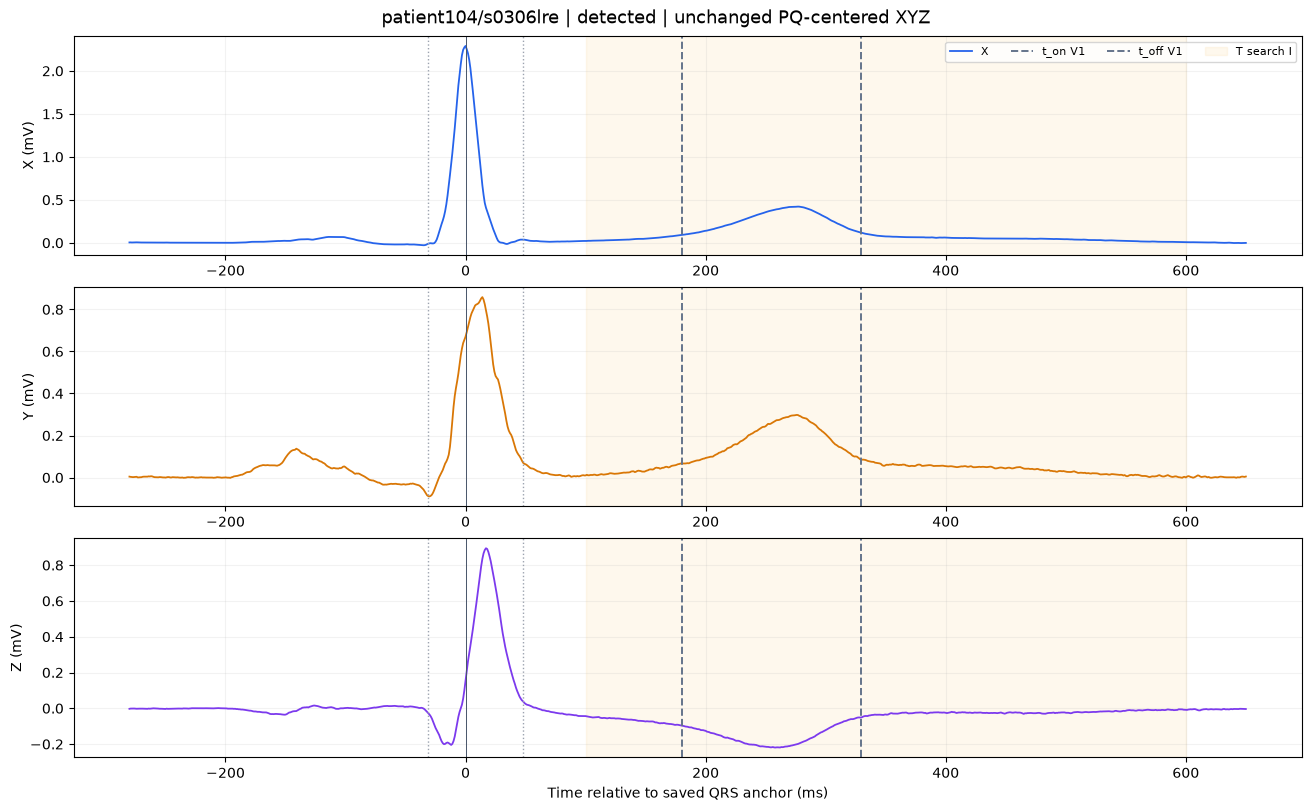

In [4]:
if available:
    t = median['time_ms']
    assert xyz_median.shape == (len(t), 3) and np.isfinite(xyz_median).all()
    assert np.array_equal(t, (np.arange(len(t))-anchor)*1000/fs)
    print('shape=', xyz_median.shape, 'fs=', fs, 'anchor=', anchor,
          'QRS samples=', (b.get('qrs_on'),b.get('qrs_off')), 'PQ slice=',median['artifact']['pq_indices'])
fig = plot_median(case, comparison=False); display(fig); plt.close(fig)

## 5. Xác định khoảng thời gian được phép tìm sóng T

**Mục đích:** giới hạn vùng tìm kiếm để chương trình tập trung vào phần tín hiệu sau QRS.

Khoảng tìm T bắt đầu sau QRS-off và ít nhất 100 ms sau mốc QRS. Điểm kết thúc phụ thuộc khoảng RR, khoảng bảo vệ trước QRS tiếp theo và độ dài nhịp đại diện thực sự có sẵn.

Trong bản thử này, RR được thay bằng trung vị các khoảng RR của bản ghi. Đây là một điều chỉnh so với cách cập nhật RR theo từng nhịp trong mã tham khảo.

Cell cũng in một khoảng dùng tính **RMS**. RMS là cách đo mức biên độ chung: bình phương các giá trị, lấy trung bình rồi lấy căn bậc hai. Giá trị này giúp đặt ngưỡng phát hiện sóng ở mục 7.

**Cách đọc kết quả:**

- `T search samples`: chỉ số đầu/cuối của khoảng được tìm T; phần `ms` là cùng khoảng đó đổi sang mili giây.
- `RMS samples`: phần dữ liệu dùng tính RMS.
- `complete RR = False`: nhịp đại diện ngắn nên không chứa trọn khoảng RR cần có; chương trình dùng phần dữ liệu hiện hữu và lưu hạn chế này.

Các mốc T của V1 không tham gia đặt khoảng tìm kiếm mới.

In [5]:
search_ready=False
search_window=rms_interval=None
if available:
    try:
        q0,q1=b.get("qrs_on"),b.get("qrs_off")
        if q0 is None or q1 is None or not 0 <= q0 < anchor < q1 < len(xyz_median):
            raise ValueError("Thiếu hoặc sai thứ tự QRS-on < anchor < QRS-off.")
        rr=float(np.median(median["artifact"]["rr_seconds"]))
        search_window=build_t_search_window(len(xyz_median),fs,anchor,q1,rr,CFG)
        rms_interval=(anchor,min(len(xyz_median)-1,anchor+int(np.floor(rr*fs+.5))))
        search_ready=True
        print("RR=",rr,"s; T search samples=",search_window,"; ms=",t[list(search_window)])
        print("RMS samples=",rms_interval,"; complete RR=",diagnostic.get("rms_interval_complete_rr","không có diagnostic"))
    except (KeyError, TypeError, ValueError) as exc:
        print("Không dựng được T search:",type(exc).__name__,str(exc))
else:
    print("Không có median: giữ trạng thái lỗi; không dựng search window giả.")

RR= 0.956 s; T search samples= (380, 880) ; ms= [100. 600.]
RMS samples= (280, 930) ; complete RR= False


## 6. Dùng wavelet để nhìn rõ sự thay đổi của tín hiệu

**Mục đích:** tạo một cách biểu diễn giúp nhận ra các sườn lên/xuống của sóng T trên từng trục X, Y, Z.

Phép biến đổi **wavelet**, viết tắt **WT**, tạo ra các dãy giá trị mới từ XYZ. Những điểm cao hoặc thấp cục bộ của dãy mới được gọi là **cực trị**; chúng giúp nhận ra các sườn của sóng. Vị trí dãy WT đổi dấu qua 0 có thể hỗ trợ tìm đỉnh hoặc đáy của sóng T.

Chương trình tính ở ba **mức quan sát** (scale): 3, 4 và 5. Mức lớn hơn xét sự thay đổi trên phạm vi thời gian rộng hơn. Các số này là mức của bộ lọc trong phương pháp, không phải độ dài cửa sổ tính bằng ms.

Loại wavelet dùng ở đây có tên *quadratic spline*. Cách tính giữ số điểm ở mọi mức bằng số điểm của XYZ, nên có thể đối chiếu trực tiếp vị trí thời gian.

**Cách đọc hình 3 × 3 bên dưới:** mỗi hàng là một trục; mỗi cột là một mức. Các dấu chấm/dấu x cho biết cực trị được chọn hoặc bỏ; các đường ngang thể hiện ngưỡng. Các giá trị trên trục đứng là hệ số WT.

**Cách đọc bảng bộ lọc:** `taps` là số hệ số của bộ lọc; `delay_samples` là độ trễ cần bù để giữ đúng thời gian; `support_radius` cho biết phạm vi các mẫu lân cận ảnh hưởng tới kết quả. Bộ lọc được điều chỉnh theo `fs`; chi tiết công thức nằm trong [tài liệu phương pháp](METHOD_REPRODUCTION.md).

,scale,taps,delay_samples,alignment,support_radius,fs_adaptation
0,3,152,74.0,exact_integer_delay,65,Kaiser polyphase equivalent-filter resampling;...
1,4,216,106.0,exact_integer_delay,97,Kaiser polyphase equivalent-filter resampling;...
2,5,344,170.0,exact_integer_delay,161,Kaiser polyphase equivalent-filter resampling;...


h= [0.125, 0.375, 0.375, 0.125] g= [2.0, -2.0]


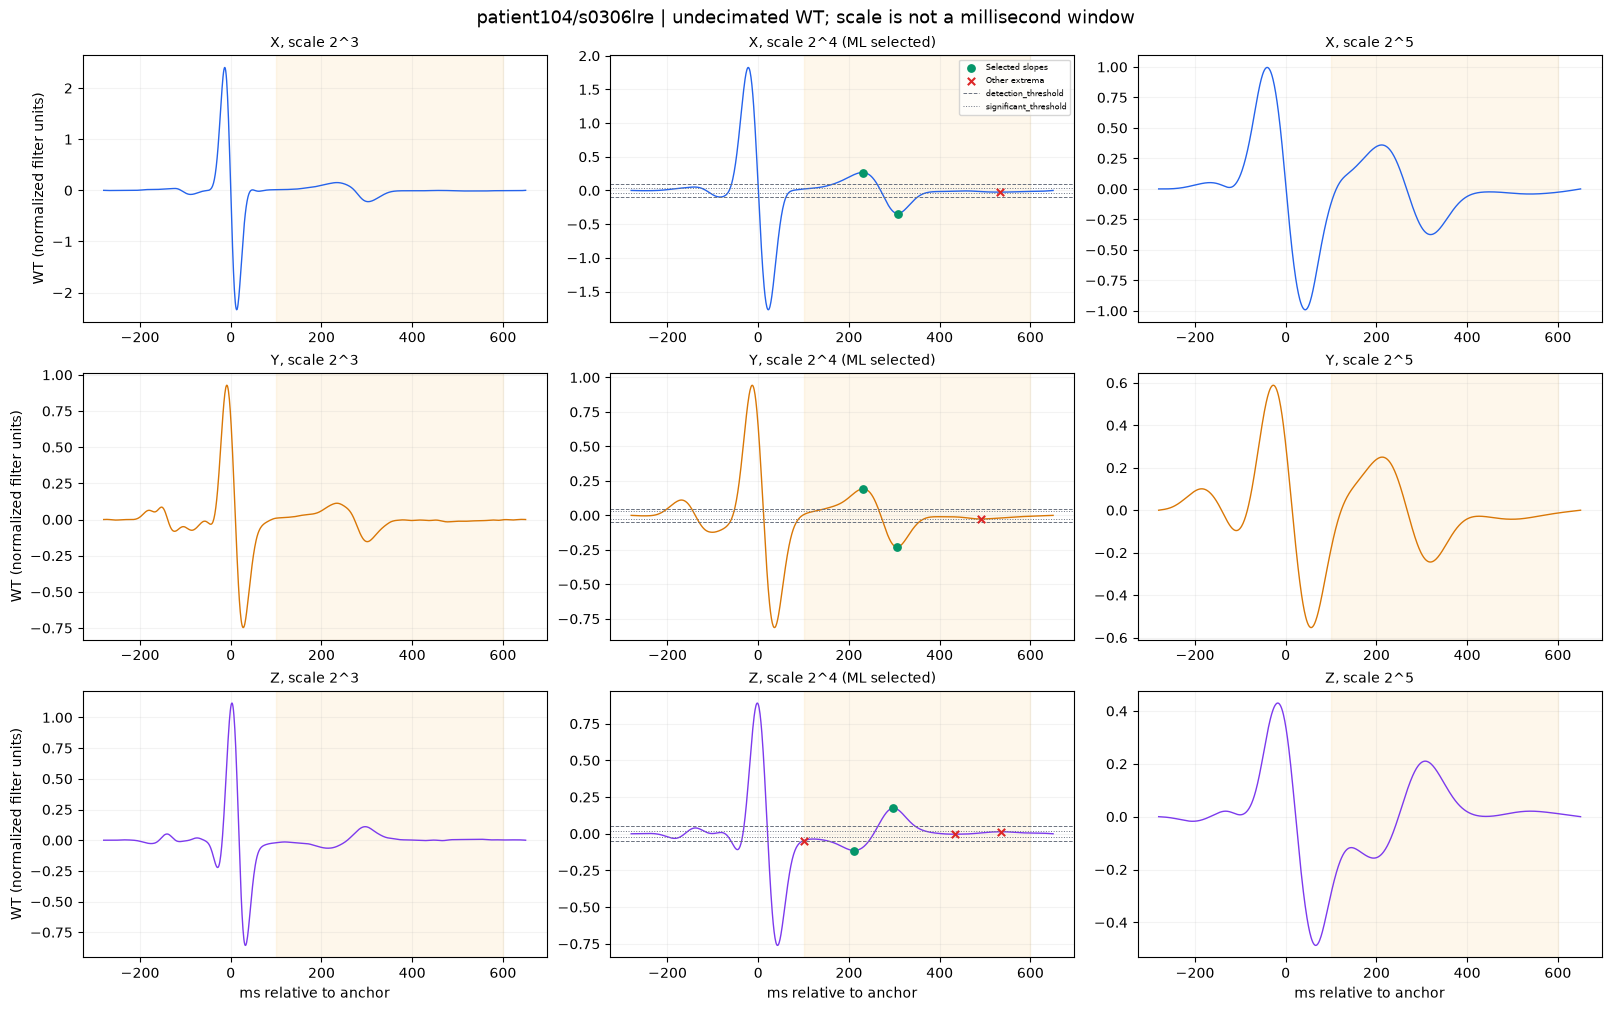

In [6]:
if available:
    wavelets, filter_bank = wavelet_transform(xyz_median,fs,CFG)
    for scale in (3,4,5):
        key='wavelet_scale'+str(scale)
        if key in arrays:
            assert np.array_equal(wavelets[scale],arrays[key])
        else:
            print("Không có wavelet cache để đối chiếu:",key,diagnostic.get("failure_reason",""))
    bank_table = pd.DataFrame([dict(scale=k, taps=len(v['coefficients']),
        delay_samples=v['delay_samples'],alignment=v['alignment'],
        support_radius=v['support_radius_samples'],fs_adaptation=v['fs_adaptation'])
        for k,v in filter_bank.items()])
    display(bank_table)
    print('h=',filter_bank['4']['h'],'g=',filter_bank['4']['g'])
fig=plot_wavelets(case); display(fig); plt.close(fig)

## 7. Tìm sóng T thử trên từng trục X, Y, Z

**Mục đích:** lấy dấu hiệu ban đầu từ từng trục trước khi kết hợp ba trục. Trong mã, bước này được gọi là `single-lead` hoặc `SL`, nghĩa là xử lý riêng từng trục.

Mỗi trục bắt đầu ở mức 4. Nếu chưa phát hiện được sóng T thì thử mức 5. Chương trình dùng ba loại ngưỡng với ba việc khác nhau:

1. **Phát hiện có sóng:** dùng `0.25 × RMS(WT)` để kiểm tra các sườn có đủ rõ.
2. **Chọn các sườn đáng kể:** dùng `0.125 × giá trị tuyệt đối lớn nhất của WT` trong vùng tìm. Giá trị tuyệt đối là độ lớn sau khi bỏ dấu âm.
3. **Tìm đầu/cuối sóng:** dò ra phía ngoài các sườn đã chọn, dùng tỷ lệ biên độ để tìm nơi sóng bắt đầu hoặc kết thúc. Bước riêng từng trục dùng tỷ lệ đầu 0.25 và cuối 0.4.

Ví dụ, nếu sườn đầu có độ lớn 0.8 thì ngưỡng đầu theo tỷ lệ là `0.25 × 0.8 = 0.2`. Đây là ví dụ tính ngưỡng, chưa phải kết quả của bản ghi.

**Cách đọc bảng:**

- `wave_detected`: đã nhận ra một sóng T ứng viên trên trục đó hay chưa.
- `candidate_sample`: vị trí mẫu đang được đề xuất; chưa phải kết quả cuối.
- `morphology_type`: dạng sóng, như dương, âm hoặc hai pha (có cả phần dương và âm).
- `only_upwards/downwards`: chỉ tìm được một sườn, chưa đủ cấu trúc để xác định một sóng T đầy đủ.
- `failure_reason`: lý do bước đó chưa có kết quả.

Hình dưới cho thấy các mốc thử của từng trục. Chương trình có thể nhận ra sóng T nhưng vẫn chưa tìm đủ cả hai biên.

,axis,wavelet_scale,wave_detected,t_peak_candidate_sample,t_on_candidate_sample,t_off_candidate_sample,first_significant_extremum,last_significant_extremum,morphology_type,detection_status,failure_reason
0,X,4,True,553,430,625,510,588,positive,detected,
1,Y,4,True,553,427,623,511,586,positive,detected,
2,Z,4,True,537,402,619,492,578,negative,detected,


,axis,scale,sample,amplitude,exceeds_detection,exceeds_significance,selected,rejection_reason,at_search_edge
0,X,4,510,0.266752,True,True,True,,False
1,X,4,588,-0.342372,True,True,True,,False
2,X,4,812,-0.024284,False,False,False,not_adjacent_to_dominant_slope,False
3,Y,4,511,0.192689,True,True,True,,False
4,Y,4,586,-0.229722,True,True,True,,False
5,Y,4,770,-0.026041,False,False,False,not_adjacent_to_dominant_slope,False
6,Z,4,380,-0.046363,False,True,False,not_adjacent_to_dominant_slope,True
7,Z,4,492,-0.114070,True,True,True,,False
8,Z,4,578,0.174660,True,True,True,,False
9,Z,4,714,-0.002765,False,False,False,below_gamma,False


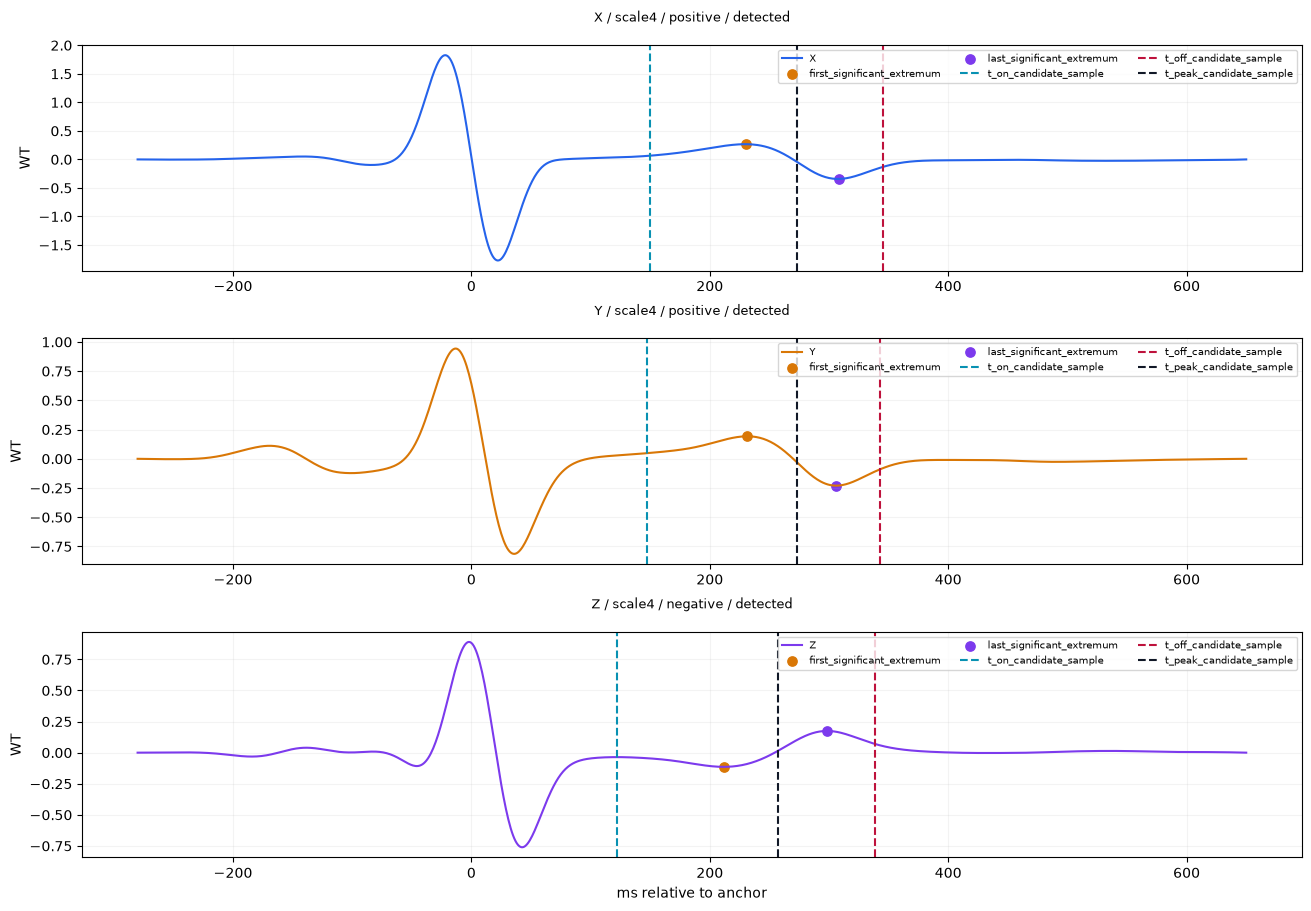

In [7]:
if search_ready:
    single_leads=single_lead_initialization(wavelets,search_window,fs,rms_interval,CFG)
    sl_columns=['axis','wavelet_scale','wave_detected','t_peak_candidate_sample',
      't_on_candidate_sample','t_off_candidate_sample','first_significant_extremum',
      'last_significant_extremum','morphology_type','detection_status','failure_reason']
    display(pd.DataFrame(single_leads)[sl_columns])
    display(pd.DataFrame([dict(axis=s['axis'],scale=a['wavelet_scale'],**e)
        for s in single_leads for a in s['attempts'] for e in a['extrema']]))
fig=plot_single_leads(case); display(fig); plt.close(fig)

## 8. Ghép ba trục wavelet thành một đường đi 3D

Ở cùng một thời điểm, ta có ba hệ số `Wx, Wy, Wz`. Coi bộ ba này là một điểm 3D rồi nối theo thứ tự thời gian, ta được **đường đi trong không gian wavelet**, gọi là *Wavelet Transform Loop*.

Đường này được dùng để tìm hướng kết hợp ba trục. T loop trên điện thế XYZ sẽ được vẽ ở mục 16.

**Cách đọc hình:** các trục `Wx, Wy, Wz` là ba hệ số wavelet. Đường xám biểu diễn phần nằm trong khoảng tìm T; các đoạn màu đánh dấu phần dữ liệu được các nhánh tìm đầu/cuối dùng để tìm hướng.

`WT loop shape = (N, 3)` nghĩa là có N thời điểm, mỗi thời điểm gồm ba hệ số. `ML scale` là mức dùng khi kết hợp nhiều trục; `ML` viết tắt của *multilead*.

WT loop shape: (931, 3) ; ML scale= 4


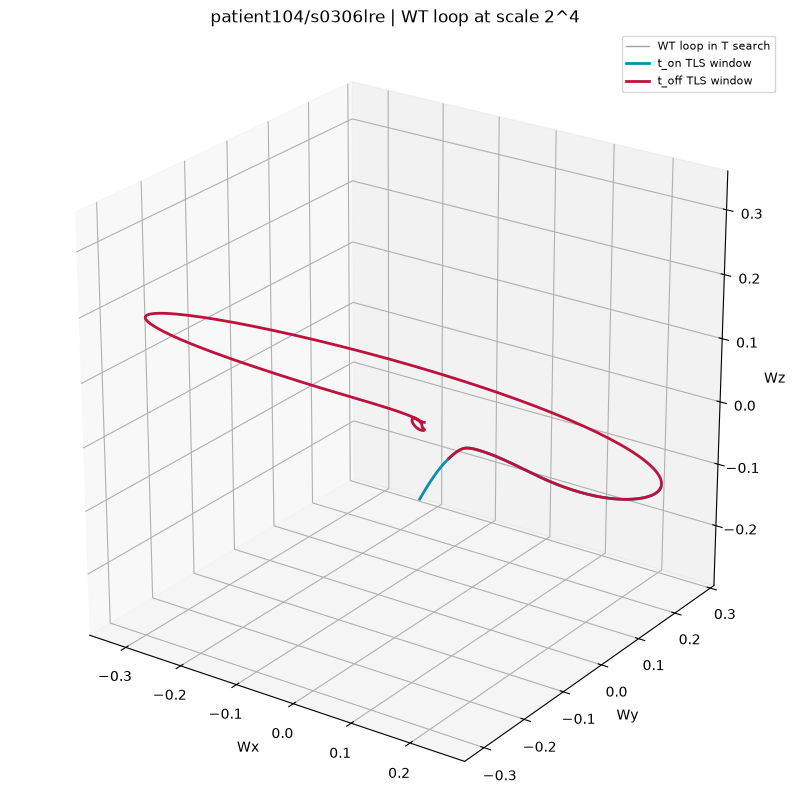

In [8]:
if search_ready:
    ml_scale=select_multilead_scale(single_leads)
    W_xyz=wavelets[ml_scale]
    print('WT loop shape:',W_xyz.shape,'; ML scale=',ml_scale)
fig=plot_wt_loop(case);display(fig);plt.close(fig)

## 9. Chọn đoạn dữ liệu ban đầu để tìm hướng

**Mục đích:** xác định những điểm 3D sẽ được dùng trong lần tìm hướng đầu tiên.

Cách chọn mức chung: dùng mức 5 nếu ít nhất hai trong ba trục phát hiện T ở mức 5; các trường hợp còn lại dùng mức 4.

Đoạn dữ liệu ban đầu bao trùm các khoảng tìm kiếm của những trục đã phát hiện T: lấy điểm bắt đầu sớm nhất và điểm kết thúc muộn nhất. Vì thí nghiệm dùng cùng QRS cho cả ba trục, các khoảng này có cùng giới hạn.

Trong phần TLS, **cửa sổ W** là một đoạn thời gian dùng để tìm hướng của đám điểm. Các ký hiệu `Wx, Wy, Wz` ở mục 8 lại là các giá trị wavelet. Cửa sổ tìm hướng W có thể được cập nhật ở các vòng sau; khoảng được phép tìm T đã nêu ở mục 5 được giữ riêng.

**Cách đọc kết quả:** `Initial TLS W samples` và phần `ms` cho biết đoạn ban đầu. Nếu cả ba trục đều không phát hiện được T thì xuất `INITIALIZATION_FAILED`, nghĩa là chưa có cơ sở để bắt đầu tìm hướng. Một trục đã phát hiện T nhưng thiếu một biên vẫn có thể hỗ trợ bước này.

In [9]:
initial_window=None
if search_ready:
    valid_sl=[s for s in single_leads if s['wave_detected']]
    if valid_sl:
        initial_window=(min(s['search_start'] for s in valid_sl),max(s['search_end'] for s in valid_sl))
        print('Initial TLS W samples=',initial_window,'; ms=',t[list(initial_window)])
        initial_fit=tls_direction(W_xyz[initial_window[0]:initial_window[1]+1],cfg=CFG)
        display(pd.Series(initial_fit,name='initial affine TLS'))
    else:
        initial_window=None
        print('INITIALIZATION_FAILED: không có single-lead T detection.')

Initial TLS W samples= (380, 880) ; ms= [100. 600.]


status                                                                    ok
direction                  [0.7716541848719324, 0.5263010554145475, -0.35...
center                     [-0.0018888475982332027, -0.001129719316542131...
singular_values            [3.93835029517107, 0.5637575635330664, 0.13158...
fit_quality                                                          0.97885
orthogonal_residual_rms                                             0.025864
Name: initial affine TLS, dtype: object

## 10. Tìm hướng quan sát để xác định đầu sóng T

**Ý tưởng:** ba trục có thể thể hiện sườn đầu T rõ khác nhau. Chương trình tìm một hướng trong không gian wavelet để gộp thông tin của cả ba.

**TLS** (*Total Least Squares*, bình phương tối thiểu toàn phần) chọn đường thẳng sao cho tổng bình phương khoảng cách vuông góc từ các điểm tới đường thẳng là nhỏ nhất. Có thể hình dung là đặt một đường thẳng đi qua đám điểm theo hướng đại diện của nó.

Đường thẳng được phép đi qua tâm đám điểm, không bị ép đi qua gốc tọa độ. Trong mã, phép tính đại số tên **SVD** được dùng để tìm đường thẳng đó.

Các đại lượng được in hoặc ghi trên hình:

- `u_on`: ba số mô tả hướng tìm đầu sóng T. Chúng được chuẩn hoá để độ dài hướng bằng 1.
- `center`: tâm đám điểm dùng khi tìm đường thẳng.
- `fit_quality` hoặc `energy fraction`: phần mức biến thiên của đám điểm nằm theo hướng đã chọn, từ 0 đến 1. Đây là số mô tả phép tìm hướng; nó không phải xác suất biên T đúng.
- `chosen iteration`: vòng lặp được chọn để lấy kết quả; cách lặp được giải thích ở mục 13.

**Cách đọc hình:** các chấm là điểm wavelet trong cửa sổ W; đường thẳng là kết quả TLS; mũi tên chỉ hướng. Nếu dữ liệu không cho một hướng xác định, nhánh này có thể chưa giải được.

T-on chosen iteration: 2 ; stop: boundary_change_strictly_less_than_two_samples
u_on= [0.7873119161421422, 0.5686276251312931, -0.23833289877424432]


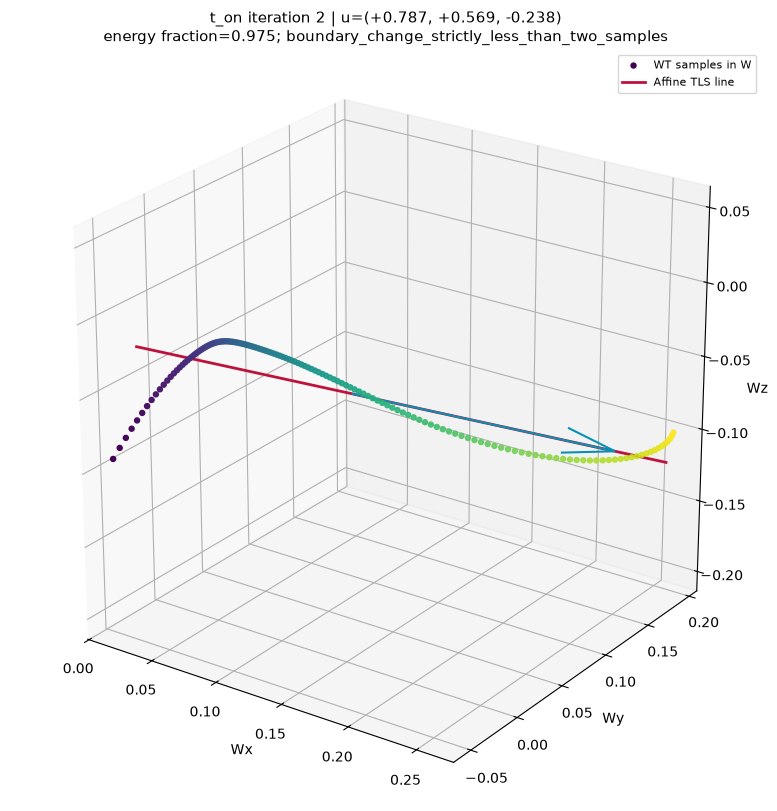

In [10]:
if available and initial_window:
    on_branch=iterate_tls_boundary(wavelets,ml_scale,initial_window,search_window,rms_interval,fs,'t_on',CFG)
    print('T-on chosen iteration:',on_branch['chosen_iteration'],'; stop:',on_branch['stop_reason'])
    print('u_on=',on_branch['direction'])
fig=plot_tls_fit(case,'t_on');display(fig);plt.close(fig)

## 11. Tìm hướng riêng cho cuối sóng T

Bước này làm tương tự mục 10 nhưng tập trung vào sườn cuối của sóng T.

Sườn đầu và sườn cuối có thể thể hiện rõ theo những hướng khác nhau. Vì vậy, chương trình có **hai nhánh tính độc lập**: nhánh T-on tìm đầu và nhánh T-off tìm cuối. Hai nhánh bắt đầu từ cùng cửa sổ, sau đó có thể cập nhật khác nhau.

**Cách đọc hình và kết quả:** `u_off` là hướng dùng cho cuối sóng; `chosen iteration` là vòng được chọn; `stop` là lý do dừng. So hình này với mục 10 để thấy hướng và vùng điểm có thay đổi hay không.

Các hướng được tìm từ dữ liệu của từng bản ghi; không có một bộ trọng số XYZ cố định dùng chung cho tất cả bản ghi.

T-off chosen iteration: 1 ; stop: no_extremum_improvement_previous_retained
u_off= [0.7716541848719324, 0.5263010554145475, -0.35715125372755885]


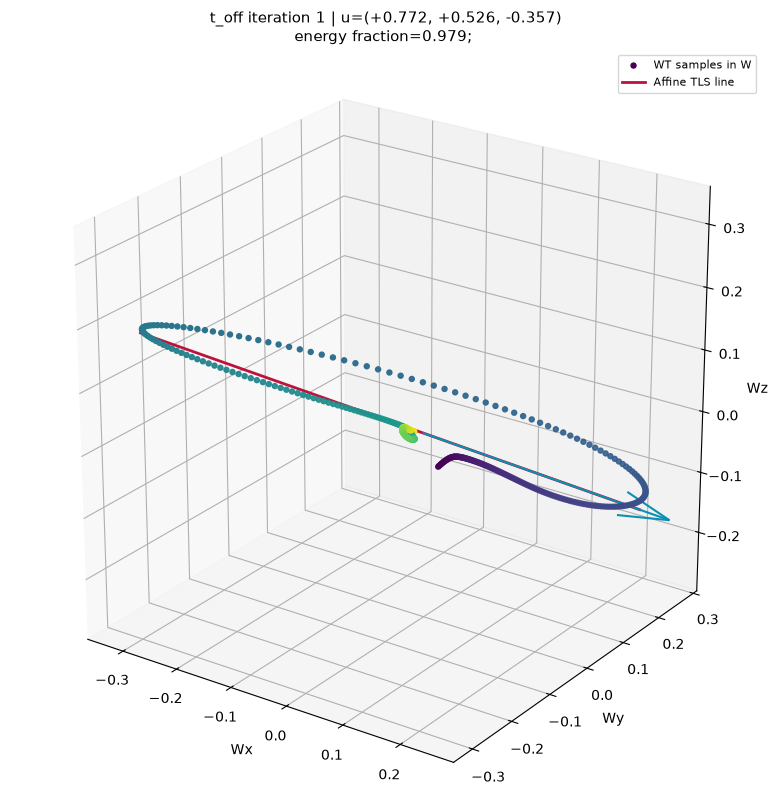

In [11]:
if available and initial_window:
    off_branch=iterate_tls_boundary(wavelets,ml_scale,initial_window,search_window,rms_interval,fs,'t_off',CFG)
    print('T-off chosen iteration:',off_branch['chosen_iteration'],'; stop:',off_branch['stop_reason'])
    print('u_off=',off_branch['direction'])
fig=plot_tls_fit(case,'t_off');display(fig);plt.close(fig)

## 12. Từ hướng 3D tạo một đường tín hiệu để tìm hai mốc

**Mục đích:** biến ba dãy wavelet thành một dãy duy nhất, dễ dò đầu hoặc cuối sóng hơn.

Chương trình nhân mỗi dãy với thành phần tương ứng của hướng `u`, rồi cộng lại:

`Wd = uX × Wx + uY × Wy + uZ × Wz`

`Wd` được gọi là **wavelet tổng hợp** (*derived wavelet*). Ví dụ, với hướng `(0.8, 0.6, 0)`, đường tổng hợp là `0.8 × Wx + 0.6 × Wy`. Mỗi nhánh T-on/T-off dùng hướng của chính nó.

Khi tìm đường thẳng, chương trình dùng các điểm đã trừ tâm. Khi tính Wd, chương trình chiếu các hệ số wavelet ban đầu theo công thức trên.

Cách tìm biên trên Wd:

- **T-on:** từ sườn đầu đáng kể, dò ngược thời gian.
- **T-off:** từ sườn cuối đáng kể, dò xuôi thời gian.
- Chọn vị trí gần sườn nhất đạt ngưỡng tương đối hoặc là một điểm thấp cục bộ của độ lớn Wd. Điểm thấp cục bộ là điểm thấp hơn các điểm lân cận.

Ở bước tổng hợp, cả ngưỡng đầu và cuối đều dùng tỷ lệ 0.25 của sườn liên quan. Với T-off, tỷ lệ này khác 0.4 ở bước riêng từng trục. Ngưỡng theo sườn cũng khác ngưỡng phát hiện `0.25 × RMS` ở mục 7.

**Cách đọc hình:** đường đậm là Wd; vùng tô là cửa sổ tìm hướng; chấm là sườn liên quan; đường đứng là mốc đang đề xuất; đường ngang là ngưỡng. Không tìm được vị trí đạt điều kiện thì giữ biên ở trạng thái thiếu.

t_on u= [0.7873119161421422, 0.5686276251312931, -0.23833289877424432] threshold= 0.08553467480925325


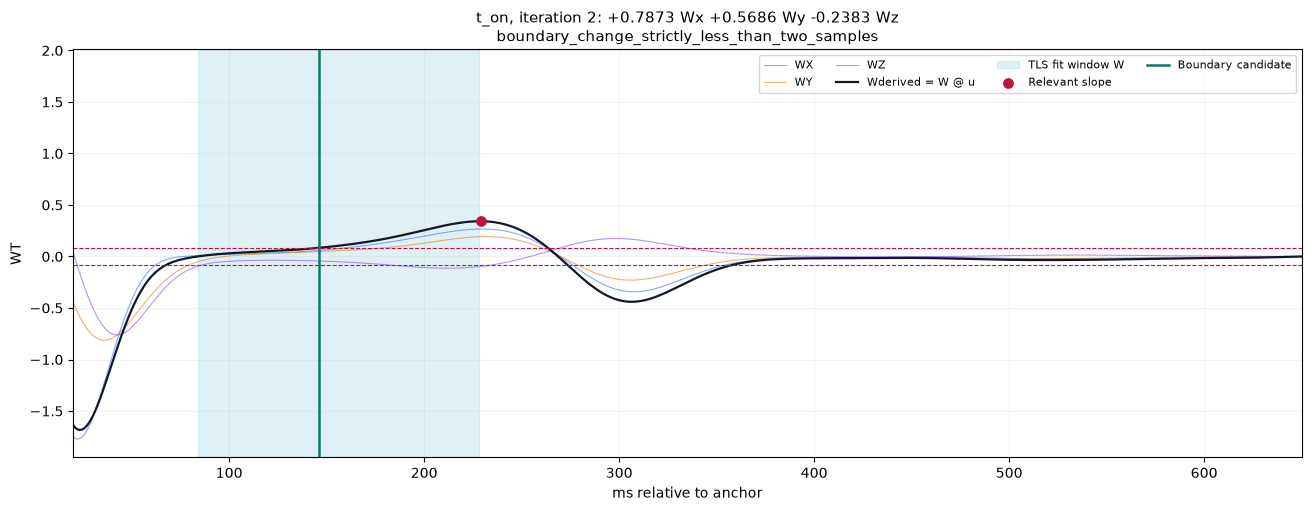

t_off u= [0.7716541848719324, 0.5263010554145475, -0.35715125372755885] threshold= 0.11115986523733107


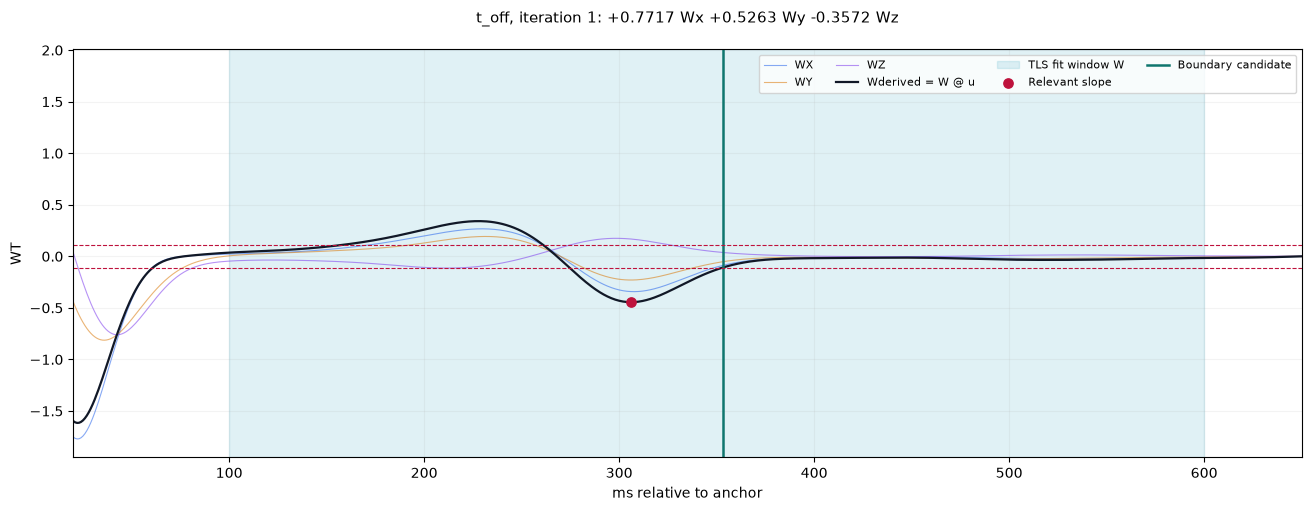

In [12]:
if search_ready:
    for boundary in ('t_on','t_off'):
        branch=diagnostic.get('branches',{}).get(boundary,{})
        if branch.get('chosen_iteration'):
            e=branch['history'][branch['chosen_iteration']-1]
            derived=project_wavelets(wavelets[ml_scale],e['direction'])
            assert np.array_equal(derived,arrays[boundary+'_derived_iterations'][e['derived_index']])
            print(boundary,'u=',e['direction'],'threshold=',e.get('boundary_threshold'))
        fig=plot_derived(case,boundary);display(fig);plt.close(fig)

## 13. Lặp lại để cập nhật hướng và quyết định lúc dừng

Một vòng lặp gồm: **chọn đoạn dữ liệu → tìm hướng → tạo Wd → tìm mốc T mới**. Sau đó chương trình dùng mốc mới để chọn đoạn dữ liệu cho vòng tiếp theo.

Cách cập nhật cửa sổ tìm hướng:

- Nhánh đầu: từ **T-on vòng trước trừ 61.2 ms** đến vị trí sườn đầu đã chọn.
- Nhánh cuối: từ vị trí sườn cuối đã chọn đến **T-off vòng trước cộng 61.2 ms**.

Số 61.2 ms bằng `4 × 15.3 ms`. Giá trị 15.3 ms được đặt cố định theo phương pháp tham khảo, hiện trong cấu hình dưới tên `sigma_cse_ms`. Các cửa sổ luôn bị giới hạn bởi dữ liệu thực sự có.

Chương trình dừng trong các trường hợp chính:

1. **Mốc đã ổn định:** hai vòng liên tiếp khác nhau ít hơn 2 mẫu. Ở 1000 Hz, chênh 0 hoặc 1 ms đạt điều kiện này; chênh đúng 2 ms thì chưa đạt.
2. **Vòng mới không tìm được sườn phù hợp hoặc không tăng biên độ sườn liên quan:** giữ kết quả đã chấp nhận ở vòng trước.
3. **Đủ 20 vòng:** dừng theo giới hạn cài đặt và ghi chưa xác nhận ổn định.

**Cách đọc bảng:** `iteration` là số vòng; `window_start/end` là giới hạn đoạn tìm hướng; `candidate_sample` là mốc thử; `accepted` cho biết vòng có được nhận không; `stop_reason` là lý do dừng. Đồ thị phía trên theo dõi vị trí mốc, phía dưới theo dõi độ lớn sườn qua các vòng.

,boundary,iteration,window_start,window_end,status,direction,center,singular_values,fit_quality,orthogonal_residual_rms,accepted,candidate_sample,stop_reason,extremum_sample,extremum_amplitude,morphology_type,derived_index,boundary_threshold
0,t_on,1,380,880,ok,"[0.7716541848719324, 0.5263010554145475, -0.35...","[-0.0018888475982332027, -0.001129719316542131...","[3.93835029517107, 0.5637575635330664, 0.13158...",0.978850,0.025864,True,425,,508,0.341477,positive,0,0.085369
1,t_on,2,364,508,ok,"[0.7873119161421422, 0.5686276251312931, -0.23...","[0.10507505533370928, 0.0690631574036114, -0.0...","[1.2552191191345001, 0.19868820369039134, 0.01...",0.975378,0.016562,True,426,boundary_change_strictly_less_than_two_samples,509,0.342139,positive,1,0.085535
2,t_off,1,380,880,ok,"[0.7716541848719324, 0.5263010554145475, -0.35...","[-0.0018888475982332027, -0.001129719316542131...","[3.93835029517107, 0.5637575635330664, 0.13158...",0.978850,0.025864,True,633,,586,0.444639,positive,0,0.111160
3,t_off,2,586,694,ok,"[0.7816314198780546, 0.514474825900112, -0.352...","[-0.11914799834077462, -0.0754175444362676, 0....","[1.5606347659671673, 0.0469200857542825, 0.021...",0.998900,0.004960,False,633,no_extremum_improvement_previous_retained,586,0.444578,positive,1,0.111144


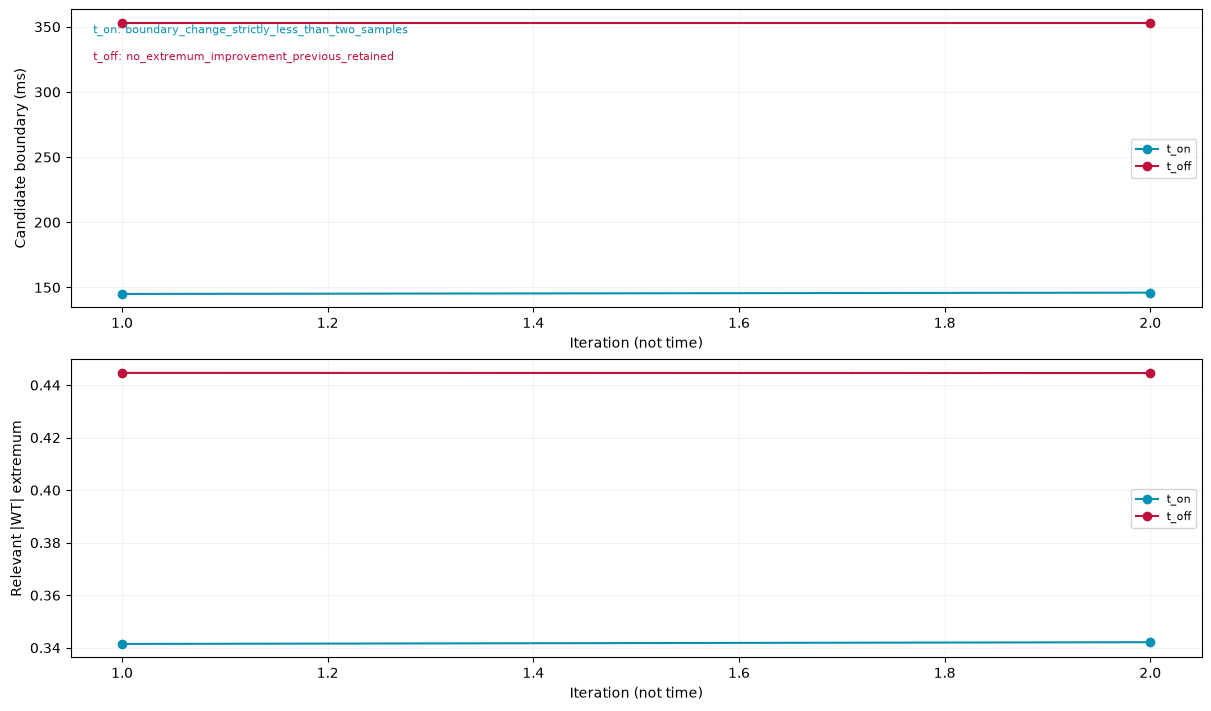

In [13]:
history_rows=[]
for boundary,branch in diagnostic.get('branches',{}).items():
    for e in branch['history']:
        history_rows.append({k:v for k,v in e.items() if k not in ('wave',)})
display(pd.DataFrame(history_rows))
fig=plot_iterations(case);display(fig);plt.close(fig)

## 14. Kiểm tra kết quả cuối có đủ điều kiện để cắt T loop

Hai mốc cuối phải nằm trong dữ liệu và theo thứ tự **QRS-off < T-on < T-off**. Các đỉnh T liên quan cũng phải phù hợp với khoảng được chọn.

**Cách đọc ba trạng thái:**

- `detected`: có đủ hai biên hợp lệ và không có cờ xem lại của bộ kiểm tra hiện tại.
- `needs_review`: có đủ biên nhưng có điều kiện cần xem lại, như khoảng T quá ngắn/dài hoặc kết quả phụ thuộc vùng mép tín hiệu.
- `unresolved`: chưa có đủ kết quả hợp lệ để tạo T loop, chẳng hạn thiếu một biên hoặc thiếu nhịp đại diện.

`t_duration_ms` là thời lượng T, bằng `T-off − T-on`. Khoảng 60–400 ms trong cấu hình chỉ dùng gắn cờ xem lại; chương trình không tự kéo hoặc cắt mốc để ép vào khoảng này.

Một biên riêng lẻ vẫn có thể được lưu khi biên còn lại thiếu. Chỉ khi có đủ cả hai biên hợp lệ mới xuất T loop. Các mốc thử và lý do thất bại vẫn nằm trong dữ liệu chẩn đoán quá trình tính.

Các trạng thái trên mô tả kết quả của chương trình. Việc xác nhận biên đúng cần mốc tham chiếu độc lập.

In [14]:
if search_ready:
    independent_result=delineate_t(xyz_median,fs,anchor,b['qrs_on'],b['qrs_off'],rr,CFG)
    for key in ('t_on_sample','t_off_sample','status','failure_reason'):
        assert independent_result.get(key)==diagnostic.get(key)
    display(pd.Series({k:independent_result.get(k) for k in ['status','failure_reason',
        't_on_sample','t_off_sample','t_on_ms','t_off_ms','t_duration_ms','review_flags']}))
else:
    print('Không đủ median/QRS/RR/search hợp lệ để đối chiếu V2; xem failure_reason ở cell chọn record.')

status            detected
failure_reason            
t_on_sample            426
t_off_sample           633
t_on_ms              146.0
t_off_ms             353.0
t_duration_ms        207.0
review_flags            []
dtype: object

## 15. Đặt kết quả V1 và V2 cạnh nhau

**Mục đích:** xem cách mới chọn hai mốc khác cách cũ bao nhiêu. Hai bên dùng cùng nhịp đại diện, nên phép so sánh này chưa đánh giá phần thông tin có thể đã mất khi tạo median.

Bốn bản ghi bên dưới được chọn từ trước:

- `patient104/s0306lre`: có đủ hai biên để xem toàn bộ quy trình.
- `patient051/s0179lre`: V1 có khoảng T dài 17 ms. V2 tìm được T-on nhưng vẫn thiếu T-off, nên chưa có T loop V2.
- `patient034/s0109lre`: V1 thiếu T-on; V2 hiện cũng chưa có đủ cặp biên.
- `patient033/s0157lre`: bước trước chưa tạo được nhịp đại diện.

**Cách đọc bảng:** hậu tố `_v1_ms` là thời gian theo cách cũ; `_v2_ms` là theo cách mới. `NaN` hoặc ô trống nghĩa là chưa có giá trị.

Khi đọc hiệu **V2 − V1**, số dương nghĩa V2 chọn muộn hơn, số âm nghĩa V2 chọn sớm hơn. Đây là chênh lệch giữa hai cách. Để gọi là sai số, cần so mỗi cách với mốc tham chiếu đã được chấp nhận.

**Cách đọc hình:** các đường đứng chỉ biên; các vùng tô cho thấy phần tín hiệu thực sự được đưa vào khoảng T của từng cách.

,record_id,t_on_v1_ms,t_on_v2_ms,t_off_v1_ms,t_off_v2_ms,status,failure_reason
0,patient104/s0306lre,180.0,146.0,329.0,353.0,detected,
1,patient051/s0179lre,246.0,169.0,263.0,NaN,unresolved,missing_t_boundary
2,patient034/s0109lre,NaN,NaN,338.0,NaN,unresolved,missing_t_boundary
3,patient033/s0157lre,NaN,NaN,NaN,NaN,unresolved,MISSING_V1_MEDIAN: ValueError: Không đủ 3 beat...


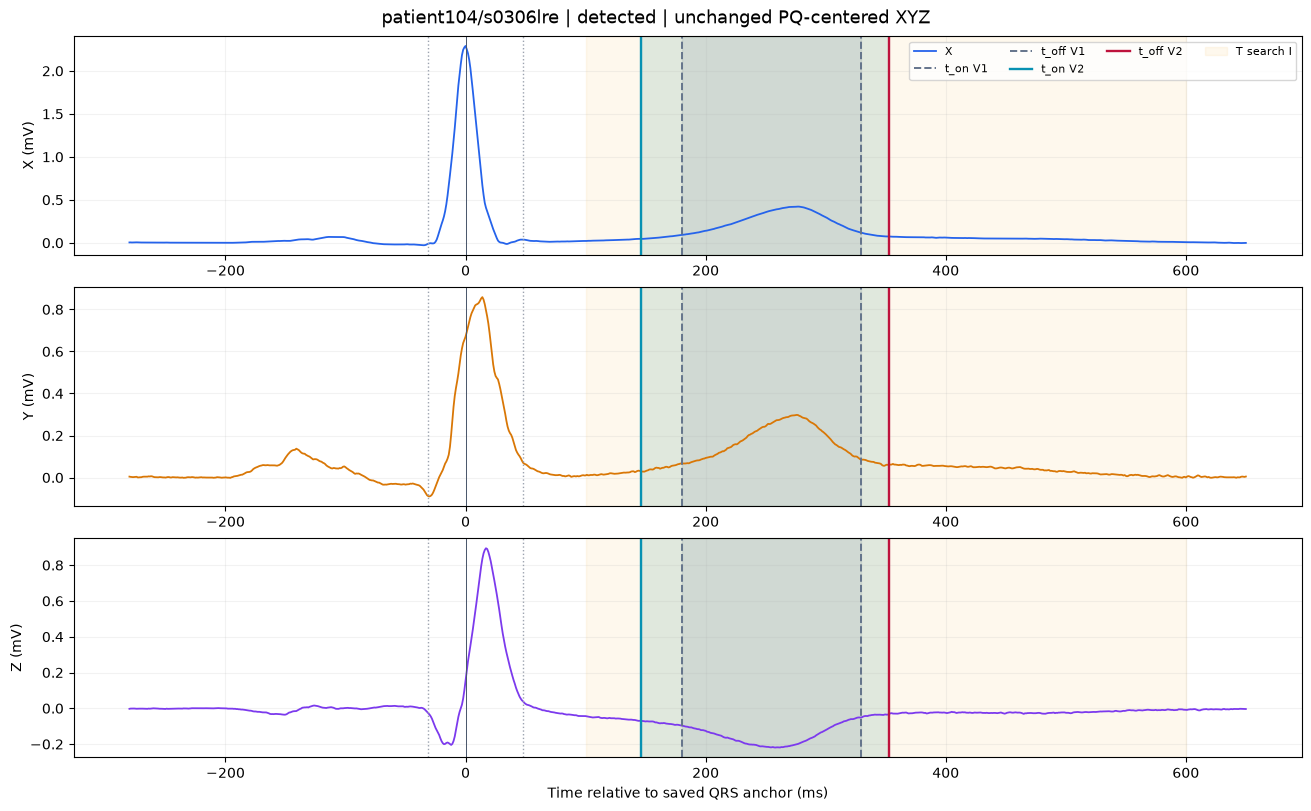

In [15]:
sample_ids=['patient104/s0306lre','patient051/s0179lre','patient034/s0109lre','patient033/s0157lre']
sample_results=[]
for rid in sample_ids:
    row=frame.set_index('record_id').loc[rid].to_dict();row['record_id']=rid
    out_row,_,_=process_one(row,OUT,CFG,V1_CFG,experiment_config['algorithm_fingerprint'],resume=True)
    sample_results.append(out_row)
sample_frame=pd.DataFrame(sample_results)
display(sample_frame[['record_id','t_on_v1_ms','t_on_v2_ms','t_off_v1_ms','t_off_v2_ms','status','failure_reason']])
fig=plot_median(case,comparison=True);display(fig);plt.close(fig)

## 16. Cắt đoạn T trên XYZ và quan sát quỹ đạo 3D

**Mục đích:** lấy các điểm XYZ từ T-on tới T-off, rồi nối chúng theo thời gian để tạo T loop.

Lệnh `cut_loop(xyz_median, on, off)` lấy **cả điểm đầu và điểm cuối**. Ví dụ, lấy từ mẫu 100 đến mẫu 200 có 101 điểm; ở 1000 Hz, khoảng thời gian giữa đầu và cuối là 100 ms.

Loop được cắt từ nhịp đại diện XYZ đã lưu ở V1. Tọa độ và mốc nền PQ được giữ để có thể so vị trí của hai loop.

**Cách đọc hình:**

- Hai hình 3D là T loop V1 và V2, dùng cùng gốc tọa độ, giới hạn trục và tỉ lệ.
- Chấm tròn chỉ điểm bắt đầu; dấu × chỉ điểm kết thúc; mũi tên chỉ chiều thời gian.
- Các hình **XY, XZ, YZ** là hình chiếu: lần lượt nhìn hai thành phần và bỏ thành phần còn lại, giúp xem phần đường đi được thêm hoặc bớt.
- Nếu thiếu một biên, ô V2 báo chưa có loop hợp lệ.

Trong phần kiểm tra của cell, QRS loop cũng được đối chiếu với khoảng cắt V1 đã lưu.

V2 loop shape= (208, 3) duration= 207.0 ms


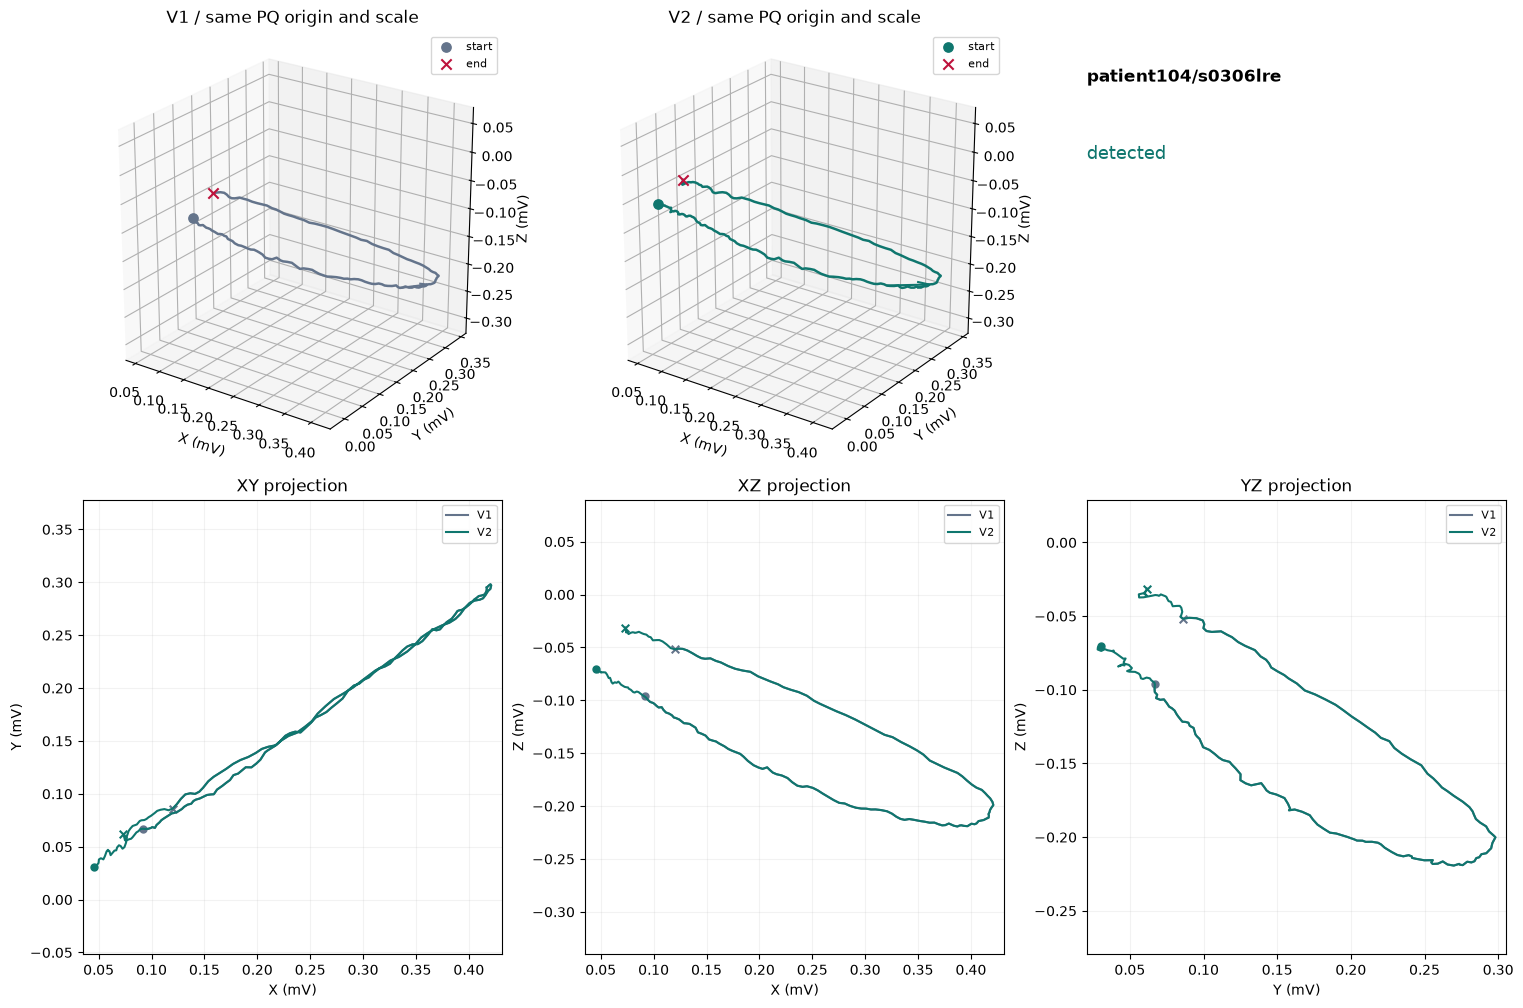

In [16]:
if available:
    on,off=diagnostic.get('t_on_sample'),diagnostic.get('t_off_sample')
    t_loop_v2=cut_loop(xyz_median,on,off)
    if t_loop_v2 is not None:
        assert np.array_equal(t_loop_v2,arrays['t_loop_v2'])
        print('V2 loop shape=',t_loop_v2.shape,'duration=',(off-on)*1000/fs,'ms')
    else:
        assert 't_loop_v2' not in arrays
        print('Không có loop V2 hợp lệ; xem failure_reason.')
    if 'qrs_loop_v1_unchanged' in arrays:
        assert np.array_equal(arrays['qrs_loop_v1_unchanged'],xyz_median[b['qrs_on']:b['qrs_off']+1])
fig=plot_t_loops(case);display(fig);plt.close(fig)

## 17. Xem kết quả của toàn bộ 448 bản ghi

Đến đây, các bước minh hoạ được mở rộng thành bảng kết quả và giao diện xem **toàn bộ danh sách nghiên cứu**, đôi khi gọi là *cohort*. Danh sách hiện có 448 bản ghi MI/HC.

- **MI**: nhóm có chẩn đoán nhồi máu cơ tim trong dữ liệu.
- **HC**: nhóm đối chứng khoẻ mạnh.
- **Manifest**: bảng danh sách ID, bệnh nhân, nhãn và tập train/valid/test đã chia sẵn.

Giao diện xem nhiều bản ghi được gọi là **gallery**. Có thể tìm ID, đổi bản ghi, xem các mức wavelet, chọn vòng TLS và xoay hình T loop 3D. Ca thiếu biên hoặc thiếu nhịp đại diện vẫn có trong danh sách.

Chương trình lưu kết quả từng bản ghi thành **điểm lưu để chạy tiếp** (checkpoint). **Cache** là các kết quả đã lưu có thể dùng lại. **Resume** là tiếp tục lần chạy, chỉ dùng lại khi dữ liệu đầu vào và cấu hình khớp.

**Cách dùng cell:** mặc định đọc kết quả đã đầy đủ. `REGENERATE_COHORT=True` yêu cầu gọi lại bước tổng hợp; các điểm lưu hợp lệ vẫn có thể được dùng lại.

[Mở gallery đủ 448 ID](outputs/vcg_t_almeida_v2_experiment/gallery/index.html). Muốn xem các trang hình của tất cả ID đã nhúng sẵn, mở [Notebook 08](08_QRS_T_Loop_Reference_Error_Analysis.ipynb), **mục 14F**.

In [17]:
REGENERATE_COHORT=False
results_path=OUT/'v2_t_boundaries.csv'
complete=results_path.exists() and set(pd.read_csv(results_path).record_id)==set(frame.record_id)
if REGENERATE_COHORT or not complete:
    run_experiment(OUT,resume=True,plots=True,gallery=True)
summary=json.loads((OUT/'execution_summary.json').read_text(encoding="utf-8"))
results=pd.read_csv(results_path)
assert set(results.record_id)==set(manifest.record_id) and results.record_id.is_unique
display(pd.Series(summary['input_counts'],name='actual V1 inputs'))
display(results.groupby(['label_name','status']).size().unstack(fill_value=0))
print('Gallery:',OUT/'gallery/index.html')
display(IFrame('outputs/vcg_t_almeida_v2_experiment/gallery/index.html',width='100%',height=780))

Processed 50/448; checkpoints reused=0
Processed 100/448; checkpoints reused=0
Processed 150/448; checkpoints reused=2
Processed 200/448; checkpoints reused=3
Processed 250/448; checkpoints reused=3
Processed 300/448; checkpoints reused=3
Processed 350/448; checkpoints reused=4
Processed 400/448; checkpoints reused=4
Processed 448/448; checkpoints reused=4
Figures 25/448
Figures 50/448
Figures 75/448
Figures 100/448
Figures 125/448
Figures 150/448
Figures 175/448
Figures 200/448
Figures 225/448
Figures 250/448
Figures 275/448
Figures 300/448
Figures 325/448
Figures 350/448
Figures 375/448
Figures 400/448
Figures 425/448
Figures 448/448


cohort             448
patients           200
medians            443
qrs_pairs          443
four_boundaries    441
Name: actual V1 inputs, dtype: int64

status,detected,needs_review,unresolved
label_name,,,
HC,59,0,21
MI,252,1,115


Gallery: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\outputs\vcg_t_almeida_v2_experiment_notebook09\gallery\index.html


## 18. Đọc các bảng tổng hợp: đủ kết quả chưa, thay đổi bao nhiêu, đúng đến đâu?

Ba điều này được báo riêng:

1. **Mức bao phủ (coverage):** có bao nhiêu bản ghi tạo được kết quả. Ví dụ, số T loop chia cho tổng 448 bản ghi khác số T loop chia cho 443 bản ghi có nhịp đại diện. Các ca thất bại vẫn được đếm.
2. **Chênh lệch giữa hai cách (disagreement):** V1 và V2 đặt mốc khác nhau bao nhiêu.
3. **Độ chính xác theo tham chiếu (reference accuracy):** mỗi cách lệch bao nhiêu so với mốc do người đánh giá độc lập xác nhận trên đúng tín hiệu.

**QC** là các kiểm tra gắn cờ cần xem lại. Số cờ ít chưa chứng minh biên đúng hơn; hai cách cũng có thể dùng các quy tắc gắn cờ khác nhau.

### Cách đọc các bảng

- Bảng bao phủ: `recordings` là số bản ghi; `medians` là số có nhịp đại diện; `both_t_boundaries` là số có đủ hai biên. `split` chỉ tập train/valid/test.
- Bảng chênh biên: `n_paired` là số ca có đủ giá trị ở cả hai cách; `median_v2_minus_v1_ms` là trung vị chênh có dấu; `median_absolute_disagreement_ms` là trung vị độ lớn chênh sau khi bỏ dấu.
- Bảng sai số: `n_reference` là số mốc tham chiếu được chấp nhận. **MAE** là trung bình độ lớn sai lệch; **RMSE** là căn bậc hai của trung bình bình phương sai lệch, nhạy hơn với sai lệch lớn. Đơn vị ở đây là ms. Khi chưa có tham chiếu, các ô này để thiếu.
- Bảng thay đổi **feature**: feature là một con số mô tả hình dạng hoặc chuyển động của loop, như độ lớn vector hay tốc độ thay đổi XYZ. `median_absolute_difference` là trung vị độ lớn thay đổi của con số đó giữa hai cách.

Các feature QRS được giữ theo V1. Feature T dùng cùng công thức V1, với tốc độ XYZ tính trên cả nhịp rồi lấy đoạn T. Tăng hoặc giảm feature tự nó chưa chứng minh khả năng phân biệt MI/HC tốt hơn.

Cell dưới cũng có phần chạy các phép kiểm thử mã. Chúng kiểm tra phép tính, điều kiện dừng và việc giữ dữ liệu nhất quán; các tín hiệu mô phỏng trong kiểm thử chưa thay thế việc xác nhận biên trên dữ liệu thật.

In [18]:
display(pd.read_csv(OUT/'reports/coverage_by_label_and_split.csv'))
display(pd.read_csv(OUT/'reports/boundary_disagreement_summary.csv'))
display(pd.read_csv(OUT/'reports/reference_error_summary.csv'))
display(pd.read_csv(OUT/'reports/feature_change_summary.csv'))
display(pd.read_csv(OUT/'diagnostics/representative_cases.csv'))
feature_comparison=pd.read_csv(OUT/'v1_v2_feature_comparison.csv')
q=feature_comparison[feature_comparison.feature.str.startswith('QRS_')]
assert q.signed_difference.dropna().eq(0).all()
print('Reference:',summary['reference'])

RUN_TESTS=True
if RUN_TESTS:
    checked=subprocess.run([sys.executable,'-m','unittest','discover','-s','tests',
        '-p','test_vcg_t_almeida.py','-v'],cwd=ROOT,text=True,capture_output=True,encoding='utf-8',errors='replace',
        env={**os.environ,'PYTHONIOENCODING':'utf-8'})
    print(checked.stdout+checked.stderr)
    assert checked.returncode==0

,group_by,group,recordings,medians,t_on_available,t_off_available,both_t_boundaries,detected,needs_review,unresolved
0,label_name,HC,80,80,59,80,59,59,0,21
1,label_name,MI,368,363,255,338,253,252,1,115
2,split,test,115,115,90,113,90,90,0,25
3,split,train,263,260,177,243,176,175,1,87
4,split,valid,70,68,47,62,46,46,0,24


,label_name,split,boundary,n_paired,median_v2_minus_v1_ms,median_absolute_disagreement_ms,interpretation
0,HC,test,t_on,10,-35.5,35.5,Disagreement only; not reference error
1,HC,test,t_off,17,23.0,23.0,Disagreement only; not reference error
2,HC,train,t_on,37,-36.0,36.0,Disagreement only; not reference error
3,HC,train,t_off,47,24.0,24.0,Disagreement only; not reference error
4,HC,valid,t_on,12,-41.0,41.0,Disagreement only; not reference error
5,HC,valid,t_off,16,24.0,24.0,Disagreement only; not reference error
6,MI,test,t_on,80,-40.5,41.0,Disagreement only; not reference error
7,MI,test,t_off,96,28.0,28.5,Disagreement only; not reference error
8,MI,train,t_on,140,-36.0,40.0,Disagreement only; not reference error
9,MI,train,t_off,196,27.0,28.0,Disagreement only; not reference error


,boundary,version,n_reference,n_paired,mean_signed_error_ms,mae_ms,rmse_ms,sd_error_ms
0,t_off,v1,0,0,NaN,NaN,NaN,NaN
1,t_off,v2,0,0,NaN,NaN,NaN,NaN
2,t_on,v1,0,0,NaN,NaN,NaN,NaN
3,t_on,v2,0,0,NaN,NaN,NaN,NaN


,label_name,feature,n_paired,median_absolute_difference,median_absolute_relative_change_pct
0,HC,QRS_Arc,80,0.000000e+00,0.000000e+00
1,HC,QRS_Area,80,0.000000e+00,0.000000e+00
2,HC,QRS_MaxCentroidDistance,80,0.000000e+00,0.000000e+00
3,HC,QRS_MaxVec,80,0.000000e+00,0.000000e+00
4,HC,QRS_MaxVel,80,0.000000e+00,0.000000e+00
5,HC,QRS_MeanVel,80,0.000000e+00,0.000000e+00
6,HC,QRS_StdVel,80,0.000000e+00,0.000000e+00
7,HC,T_Area,59,2.179658e-03,1.034450e+01
8,HC,T_MaxVec,59,0.000000e+00,0.000000e+00
9,HC,T_MaxVel,59,0.000000e+00,0.000000e+00


,record_id,selection,source
0,patient104/s0306lre,user_preselected,task before V2 execution
1,patient051/s0179lre,user_preselected,task before V2 execution
2,patient034/s0109lre,user_preselected,task before V2 execution
3,patient033/s0157lre,user_preselected,task before V2 execution
4,patient001/s0010_re,first_train_valid_SL_negative,"SL algorithm morphology, not independently ver..."
5,patient006/s0064lre,first_train_valid_SL_biphasic_positive_negative,"SL algorithm morphology, not independently ver..."
6,patient023/s0103lre,first_train_valid_SL_biphasic_negative_positive,"SL algorithm morphology, not independently ver..."
7,patient282/s0539_re,minimum_available_WT_RMS_proxy,WT RMS proxy only; not verified flat T morphology
8,patient001/s0010_re,first_train_valid_V1_st_level_requires_review,V1 QC flag; not reference error
9,patient032/s0106lre,first_train_valid_V1_t_end_methods_disagree,V1 QC flag; not reference error


Reference: {'source': 'C:\\Users\\tuyet\\OneDrive\\Máy tính\\vcg\\VCG\\outputs\\vcg_boundary_reference_eval_v1\\reference_annotations.csv', 'accepted_reference_boundaries': 0, 'accepted_t_boundaries': 0, 'ground_truth_available': False, 'accuracy_claim': 'Unavailable without accepted compatible independent reference'}
Processed 1/1; checkpoints reused=0
test_full_reporting_and_gallery_for_only_missing_median (test_vcg_t_almeida.TestFrozenPTBIntegration.test_full_reporting_and_gallery_for_only_missing_median) ... c:\Users\tuyet\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\tuyet\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\tuyet\AppData\Local\Programs\Python\Python311\Lib\site-packages\n

## 19. Kết luận hiện tại và những điểm còn cần kiểm tra

Notebook cho thấy cách tìm biên T và vẽ loop trên **nhịp đại diện đã lưu**. Có được một loop nghĩa là chương trình đã tìm đủ biên theo các điều kiện cài đặt; việc đánh giá độ đúng và giá trị phân biệt bệnh cần thêm bằng chứng.

Những hạn chế chính:

- **Gộp nhịp bằng trung vị có thể làm yếu đặc điểm chỉ có ở ít nhịp.** Cần xem các nhịp riêng và mức thay đổi giữa các nhịp để đánh giá thông tin phân biệt MI/HC có bị mất hay không. So V1 với V2 trên cùng median chưa trả lời được câu hỏi này.
- Nhịp đại diện chỉ chứa một đoạn thời gian ngắn. Vì vậy, khoảng RR và mức RMS trong bản thử được tính từ dữ liệu hiện có; cách xử lý vùng mép và điều chỉnh bộ lọc cũng có thể ảnh hưởng biên.
- Chưa có đối chiếu đầu ra với chương trình của nhóm tác giả để xác nhận tương đương toàn bộ phương pháp.
- Chưa có mốc T tham chiếu độc lập được chấp nhận để kết luận V1 hay V2 chính xác hơn.

Một bước nghiên cứu phù hợp tiếp theo là đối chiếu **feature từ median** với **feature của từng nhịp và độ biến thiên giữa các nhịp**, trước hết trên train/valid. Nhịp có giá trị khác phần lớn các nhịp khác chưa đủ để kết luận là nhiễu, cũng chưa đủ để kết luận mang dấu hiệu MI.

### Mở các kết quả đã lưu

- [Gallery: tìm theo ID, xem từng vòng và T loop 3D](outputs/vcg_t_almeida_v2_experiment/gallery/index.html).
- [Notebook 08, mục 14F: hình của toàn bộ 448 ID](08_QRS_T_Loop_Reference_Error_Analysis.ipynb).
- [Báo cáo kết quả](outputs/vcg_t_almeida_v2_experiment/reports/experiment_report.md).
- [Nguồn, công thức và các điều chỉnh của phương pháp](METHOD_REPRODUCTION.md).

Để chạy lại toàn bộ thí nghiệm từ thư mục gốc project:

```bash
python scripts/run_vcg_t_almeida_experiment.py
```

Cell cuối kiểm tra mã nội dung các file V1 và hiển thị báo cáo chi tiết. Báo cáo này là tài liệu kỹ thuật; các mục phía trên giải thích các khái niệm cần để đọc nó.

In [19]:
integrity=verify_v1(protected)
display(pd.Series(integrity))
assert integrity['changed_files']==0
display(Markdown((OUT/'reports/experiment_report.md').read_text(encoding="utf-8")))
write_json(OUT/'reports/notebook09_integrity.json',integrity)

protected_files    1834
changed_files         0
v1_unchanged       True
dtype: object

# Notebook 09 — Thí nghiệm T delineation Wavelet/TLS

## Phạm vi và mức tái hiện

Tái dựng các công thức quadratic-spline WT và vòng lặp TLS của Almeida (2009), sử dụng single-lead Martínez (2004). Đây là **reconstruction có điều chỉnh được ghi rõ**, không phải bản port bit-exact của wavedet. Xem `../../../METHOD_REPRODUCTION.md`.

Nguồn: [Almeida 2009](https://doi.org/10.1109/TBME.2009.2021658), [Martínez 2004](https://doi.org/10.1109/TBME.2003.821031), [mã tham khảo cố định](https://github.com/marianux/ecg-kit/tree/c8e3de47c54a9214138143676d2aa546b0540dd2/common/wavedet).

Đúng công thức: h=[1,3,3,1]/8, g=2[1,-1], bank à trous không decimation; epsilon=0.25 RMS, gamma=0.125 max; Ton=0.25 slope, SL Toff=0.4 slope, ML Toff=0.25 slope; chọn scale5 khi ≥2 trục phát hiện ở scale5; hai hướng TLS affine khác nhau; sigma=15.3 ms, cập nhật W và dừng <2 native samples hoặc cực trị không cải thiện.

Điều chỉnh: resample hệ số bằng Kaiser polyphase; reflect-padding và cảnh báo biên; median RR thay recursive RR; RMS tính trên phần median có sẵn; cửa sổ dùng QRS V1 chung; thiếu tiêu chí biên trả unresolved thay vì fallback tới mép; SVD giải TLS thay nonlinear optimizer. Chi tiết cực trị theo mã 2011–2012 không được coi là chính xác lịch sử 2004/2009.

## Dữ liệu và kết quả chạy thực tế

Đọc 448 IDs. Số median hợp lệ: 443; số QRS-pair V1: 443; số đủ bốn biên V1: 441. Các số được tính lại từ input, không điền theo mô tả nhiệm vụ.

V2 tạo được 312 T loops (70.43% trên median; 69.64% trên toàn cohort). Trạng thái: {"detected": 311, "unresolved": 136, "needs_review": 1}. Exceptions: 0.

Các trạng thái detected/needs_review mô tả điều kiện của thuật toán, không xác nhận biên sinh lý đúng. Xem `coverage_by_label_and_split.csv` cho phân bố HC/MI và split.

QC V2 chỉ kiểm tra những điều kiện đã khai báo cho thí nghiệm; QC V1 được giữ ở các cột riêng. Không so trực tiếp số needs_review V1/V2 để khẳng định chất lượng tăng. Kết quả chỉ giải được một biên vẫn giữ biên đó, nhưng không xuất T loop.

## Ca smoke được chỉ định trước

- `patient104/s0306lre`: V1 T=[180, 329] ms; V2=[146, 353] ms; **detected**. 
- `patient051/s0179lre`: V1 T=[246, 263] ms; V2=[169, missing] ms; **unresolved**. missing_t_boundary
- `patient034/s0109lre`: V1 T=[missing, 338] ms; V2=[missing, missing] ms; **unresolved**. missing_t_boundary
- `patient033/s0157lre`: V1 T=[missing, missing] ms; V2=[missing, missing] ms; **unresolved**. MISSING_V1_MEDIAN: ValueError: Không đủ 3 beat sau kiểm tra biên/RR/lỗi dữ liệu.

Không chọn ví dụ dựa trên V2 đẹp hơn; bốn ca trên được yêu cầu trước khi chạy. Gallery giữ mọi ID, bao gồm ca thiếu median.

![Ca T rõ được chỉ định trước: V1/V2 trên XYZ](../figures/patient104_s0306lre_comparison.png)

![Ca17ms V1: V2 còn thiếu T-off, không ép tạo loop](../figures/patient051_s0179lre_comparison.png)

## Thiếu kết quả và nguyên nhân

Các cột `t_on_failure_reason` và `t_off_failure_reason` trong v2_t_boundaries.csv giữ lý do chi tiết của từng nhánh (extrema, zero crossing, threshold/local minimum hoặc TLS). `failure_reason=missing_t_boundary` chỉ là trạng thái tổng quát của khoảng T.

- missing_t_boundary: 129 recordings.
- MISSING_V1_MEDIAN: ValueError: Không đủ 3 beat sau kiểm tra biên/RR/lỗi dữ liệu.: 5 recordings.
- INITIALIZATION_FAILED_all_three_single_leads_unresolved: 2 recordings.

## V1/V2, reference và features

`boundary_disagreement_summary.csv` báo chênh V2−V1 theo HC/MI và split. Đây là độ bất đồng; không phải sai số so với chuẩn.

Có 0 reference boundaries được validator chấp nhận, trong đó 0 biên T. Các ô MAE/RMSE thiếu reference được giữ NaN; xem reference_error_summary.csv.

QRS features giữ nguyên V1. T features gọi đúng extract_features V1 với spatial_speed tính trên toàn median rồi mới cắt, tránh đạo hàm lại ở mép loop. V1 được tái tạo và kiểm tra parity trước khi so sánh. `feature_change_summary.csv` báo mức thay đổi theo feature/nhãn; tăng/giảm không thể hiện tốt/xấu.

- HC: median |relative change| (%): T_Area=10.34; T_MaxVec=0.00; T_MaxVel=0.00; T_MeanVel=17.09; T_StdVel=6.63.
- MI: median |relative change| (%): T_Area=18.20; T_MaxVec=0.00; T_MaxVel=0.00; T_MeanVel=14.27; T_StdVel=7.76.

## Tái lập, bảo vệ V1 và giới hạn

1834 file V1 được hash trước/sau; changed=0. Manifest byte-identical=True. Config/engine được khóa trước khi chạy test; không huấn luyện lại ML, không chọn ngưỡng theo nhãn/test.

Checkpoint kiểm tra engine/config, source row và SHA256 JSON/NPZ median; cache intermediate đủ tái tạo. Chạy lại bằng lệnh trong README của thí nghiệm.

Không có fixture numerical từ tác giả hoặc bản chạy MATLAB để chứng minh equivalence; bank modern dfilt MAT không được dùng vì là đối tượng MATLAB opaque, không được giả gọi là coefficients gốc. Median khác beat lâm sàng gốc; border/RMS/RR adaptations có thể thay kết quả. T dẹt, thiếu cặp slopes hoặc đơn điệu có thể unresolved. TLS tối đa hóa hướng biến thiên theo giả định noise đồng nhất, không bảo đảm hướng biên sinh lý tối ưu.

Bước tiếp: chú giải độc lập trên đúng median (ưu tiên cả ca có/không cảnh báo), đánh giá Ton/Toff và ảnh hưởng features; kiểm tra đối chiếu tác giả/MATLAB và adaptation sensitivity trên train/valid trước khi quyết định thay V1. **Chưa có căn cứ kết luận Almeida/V2 tốt hơn V1.**

## Ví dụ bổ sung có quy tắc chọn công khai

Mỗi nhóm chọn ID đầu theo thứ tự hoặc cực trị proxy đã nêu trên train/valid; không chọn theo V2 tốt hơn. Morphology tự động và QC không được coi là annotation độc lập.
- `patient001/s0010_re`: first_train_valid_SL_negative (SL algorithm morphology, not independently verified; axis=Y).
- `patient006/s0064lre`: first_train_valid_SL_biphasic_positive_negative (SL algorithm morphology, not independently verified; axis=X).
- `patient023/s0103lre`: first_train_valid_SL_biphasic_negative_positive (SL algorithm morphology, not independently verified; axis=Z).
- `patient282/s0539_re`: minimum_available_WT_RMS_proxy (WT RMS proxy only; not verified flat T morphology).
- `patient001/s0010_re`: first_train_valid_V1_st_level_requires_review (V1 QC flag; not reference error).
- `patient032/s0106lre`: first_train_valid_V1_t_end_methods_disagree (V1 QC flag; not reference error).
- `patient193/s0008_re`: largest_V1_QRS_duration_train_valid (Duration proxy, not independently classified abnormal QRS).

## Kiểm thử và giao diện


Gallery offline: [mở toàn cohort](../gallery/index.html). Test log: `../logs/test_run.log`.


## Phụ lục mới — cùng giao thức so sánh V1 / V2 / V3

Phần từng bước V2 phía trên giữ nguyên. Phụ lục này chạy lại từ raw cùng config và evaluate cả ba method trên cùng median để tránh so các CSV từ những lần chạy khác nhau. Cùng bộ hàm, option và metric được nhúng trực tiếp trong notebook 05, 09 và 10; không cần chạy script sinh notebook hoặc phụ thuộc output V3.

Chạy từ cell cấu hình dưới đến hết phụ lục. Muốn đối chiếu ba notebook: đặt cùng CX_DEMO_ID, seconds, scope, limit, tolerance, seeds và cấu hình; kiểm tra protocol ID và signal hash giống nhau. Mặc định chỉ demo; cohort/full ML là option chủ động. Hướng dẫn từng bước V3 xem notebook 10.

Nếu các mục cũ phía trên đang tự chạy batch/prerequisites thì chúng thuộc workflow cũ; có thể chạy riêng toàn bộ phụ lục này vì nó tự import và đọc raw. Data raw cần có sẵn tại content/ptbdb/.../1.0.0; các JSON/split ở data/ chỉ là manifest.

In [20]:
CX_NOTEBOOK = "09_VCG_T_Loop_Almeida_Wavelet_TLS_Experiment.ipynb"
from pathlib import Path
from dataclasses import asdict, replace
from itertools import combinations, product
import hashlib, json, sys, time, copy, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

CX_ROOT = next((p for p in [Path.cwd(), Path.cwd() / "VCG", *Path.cwd().parents]
                if (p / "vcg_pipeline.py").is_file()), None)
if CX_ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục vcg/VCG hoặc vcg.")
CX_ROOT = CX_ROOT.resolve()
if str(CX_ROOT) not in sys.path: sys.path.insert(0, str(CX_ROOT))
from vcg_preprocessing import Config, assess_input_quality, welch_xyz
from vcg_pipeline import (FEATURE_NAMES, load_xyz, preprocess_xyz, detect_qrs_anchors,
    representative_beat, delineate_loops, cut_loop, extract_features, spatial_speed,
    project_pca, flattest_pq, ms_samples, plot_delineation)
from vcg_t_almeida import AlmeidaConfig, delineate_t, wavelet_transform, json_safe

# Cùng các giá trị này trong 05, 09 và 10 để so sánh được.
CX_DATA_ROOT = CX_ROOT / "content/ptbdb/physionet.org/files/ptbdb/1.0.0"
CX_DEMO_ID = "patient104/s0306lre"
CX_RUN_COHORT = False
CX_COHORT_LIMIT = 20           # None = toàn bộ phạm vi đã chọn
CX_SCOPE = "train_valid"       # train_valid / test / all
CX_SECONDS = 30.0
CX_TOLERANCE_MS = 25.0
CX_MIN_VOTES = 2
CX_DURATION_MS = (60.0, 400.0)  # màn kiểm tra chung; không clip/ép kéo dài sóng
CX_NOISE_LEVELS = (0.005, 0.01, 0.02)
CX_SEEDS = (0, 1, 2, 3, 4)
CX_RUN_STABILITY = True        # chỉ demo; noise lên median; raw anchors/RR cố định
CX_RUN_BOOTSTRAP = False       # resample beats; đắt hơn
CX_BOOTSTRAP_REPEATS = 10
CX_RUN_SENSITIVITY = True
CX_RUN_ML = False              # chỉ có ý nghĩa khi đủ cohort train/val/test
CX_SAVE_REPORTS = False
CX_SAVE_FIGURES = False
CX_RUN_TAG = "comparison_01"   # đổi khi thay cấu hình hoặc thực hiện final test
CX_V1_CFG, CX_V2_CFG = Config(seconds=CX_SECONDS), AlmeidaConfig()
CX_METHODS = ("V1", "V2", "C", "V3")
CX_COLORS = {"V1":"#d97706", "V2":"#7c3aed", "C":"#0891b2", "V3":"#dc2765"}
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"font.family":"DejaVu Sans", "figure.dpi":105, "font.size":10})

def cx_file_hash(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024*1024), b""): h.update(block)
    return h.hexdigest()

def cx_signal_hash(xyz):
    return hashlib.sha256(np.ascontiguousarray(xyz, dtype="<f8").tobytes()).hexdigest()

def cx_index(value, n):
    try: return np.isfinite(value) and int(value) == value and 0 <= int(value) < n
    except (TypeError, ValueError, OverflowError): return False

def cx_ms(value, st):
    return (int(value)-st["rep"]["anchor"])*1000/st["fs"] if cx_index(value,len(st["rep"]["xyz"])) else np.nan

CX_SPLIT = pd.read_csv(CX_ROOT / "data/split_manifest.csv")
CX_SPLIT["split"] = CX_SPLIT["split"].replace({"valid":"val", "validation":"val"})
assert CX_SPLIT.record_id.is_unique, "record_id lặp trong split manifest"
assert CX_SPLIT.groupby("patient_id").split.nunique().max() == 1, "Patient leakage!"
assert CX_SPLIT.groupby("patient_id").label_name.nunique().max() == 1, "Patient label mismatch"
assert CX_SPLIT.label_name.isin(["MI","HC"]).all()
_cx_notebook = json.loads((CX_ROOT/CX_NOTEBOOK).read_text(encoding="utf-8"))
_cx_shared_sources = ["".join(c["source"]) for c in _cx_notebook["cells"]
                      if "cx_shared_definition" in c.get("metadata",{}).get("tags",[])]
CX_SHARED_CODE_SHA256 = hashlib.sha256("\n".join(_cx_shared_sources).encode()).hexdigest()
cx_config = dict(shared_code_sha256=CX_SHARED_CODE_SHA256, protocol="vcg-shared-unlabeled-1.0", seconds=CX_SECONDS,
    tolerance_ms=CX_TOLERANCE_MS, min_votes=CX_MIN_VOTES, duration_ms=CX_DURATION_MS,
    v1=asdict(CX_V1_CFG), v2=asdict(CX_V2_CFG), scope=CX_SCOPE,
    noise_levels=CX_NOISE_LEVELS, seeds=CX_SEEDS,
    files_manifest_sha256=cx_file_hash(CX_ROOT/"data/ptbdb-files.json"),
    resources_sha256=cx_file_hash(CX_ROOT/"data/resources.json"),
    split_sha256=cx_file_hash(CX_ROOT/"data/split_manifest.csv"),
    source_sha256={p:cx_file_hash(CX_ROOT/p) for p in
        ["vcg_pipeline.py","vcg_preprocessing.py","vcg_t_almeida.py"]})
CX_PROTOCOL_ID = hashlib.sha256(json.dumps(cx_config,sort_keys=True).encode()).hexdigest()[:16]
CX_OUT = CX_ROOT/"outputs"/"vcg_shared_comparison"/Path(CX_NOTEBOOK).stem/(CX_RUN_TAG+"_"+CX_PROTOCOL_ID)
CX_RESULTS = {}
def cx_show(fig, name):
    # Nhúng PNG tĩnh để VS Code/Jupyter không phụ thuộc widget/backend hiện tại.
    from io import BytesIO
    from IPython.display import Image
    fig.canvas.draw()
    with BytesIO() as png:
        fig.savefig(png,format="png",dpi=plt.rcParams["figure.dpi"],bbox_inches="tight")
        display(Image(data=png.getvalue()))
    if CX_SAVE_FIGURES:
        CX_OUT.mkdir(parents=True, exist_ok=True)
        fig.savefig(CX_OUT/(name+".png"), dpi=180, bbox_inches="tight")
    plt.close(fig)
print("Root:", CX_ROOT, "\nData:", CX_DATA_ROOT, "\nProtocol:", CX_PROTOCOL_ID)
print("Output:", CX_OUT, "\nCohort:", CX_RUN_COHORT, "| scope:", CX_SCOPE)

Root: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG 
Data: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\content\ptbdb\physionet.org\files\ptbdb\1.0.0 
Protocol: e8ad37a4786a1198
Output: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\outputs\vcg_shared_comparison\09_VCG_T_Loop_Almeida_Wavelet_TLS_Experiment\comparison_01_e8ad37a4786a1198 
Cohort: False | scope: train_valid


### Bộ hàm đồng bộ (có thể mở cell để đọc)

V1/V2/C được adapter vào cùng schema, V3 dùng joint complete-link consensus. Cùng bộ kiểm tra thứ tự, duration, input flags và feature extraction được dùng cho mọi method. Flags native vẫn được giữ. Code/hash phải giống trong cả ba notebook.

In [21]:
def cx_load_state(rid):
    started = time.perf_counter()
    raw = load_xyz(CX_DATA_ROOT / rid, CX_V1_CFG.seconds)
    fs = raw["fs"]
    morph, detection, prep = preprocess_xyz(raw["xyz"], fs, CX_V1_CFG, return_diagnostics=True)
    detector = detect_qrs_anchors(morph, detection, fs, CX_V1_CFG)
    rep = representative_beat(morph, detector["anchors"], fs, CX_V1_CFG, quality=prep["input_quality"])
    common_flags = sorted(set(detector["flags"] + rep["quality_flags"] +
                             prep.get("warnings", [])))
    if rep["n_used"] < 5: common_flags.append("few_representative_beats")
    if rep["n_excluded"]/max(len(detector["anchors"]),1) > .4:
        common_flags.append("many_excluded_beats")
    return dict(record_id=rid, raw=raw, fs=fs, morph=morph, detection=detection,
                preprocessing=prep, detector=detector, rep=rep,
                common_flags=sorted(set(common_flags)),
                shared_seconds=time.perf_counter()-started)

def cx_order(st, b):
    n = len(st["rep"]["xyz"])
    q0,q1,on,off = [b.get(k) for k in ("qrs_on","qrs_off","t_on","t_off")]
    if not all(cx_index(v,n) for v in (q0,q1,on,off)): return False
    if not q0 < st["rep"]["anchor"] < q1 < on < off: return False
    peaks = b.get("peaks", [])
    return all(cx_index(p,n) and on < p < off for p in peaks if p is not None)

def cx_hard_flags(st, b, valid, plausible):
    # QC/morphology warnings remain visible but do not erase a valid
    # candidate. Only data/pipeline/order failures block accepted.
    hard=[];quality=st.get("preprocessing",{}).get("input_quality",{})
    if quality.get("invalid_samples",0):hard.append("input_qc_fail")
    if not valid:hard.append("invalid_or_missing_T_pair")
    if valid and not plausible:hard.append("duration_review")
    for f in b.get("flags",[]):
        if f.startswith(("missing_","no_","error","invalid_","threshold_crossing_missing")):hard.append(f)
    return sorted(set(hard))

def cx_derivative(st, q):
    # C là magnitude-baseline threshold kiểm tra chéo, không phải detector độc lập.
    from scipy.signal import savgol_filter, find_peaks
    fs,rep=st["fs"],st["rep"]; xyz=rep["xyz"]; n=len(xyz)
    out=dict(method="C",status="unresolved",flags=[],qrs_on=q.get("qrs_on"),qrs_off=q.get("qrs_off"),
             t_on=None,t_off=None,peaks=[],trace={})
    if not cx_index(q.get("qrs_off"),n):
        out["flags"]=["missing_qrs_off"]; return out
    win=min(n if n%2 else n-1, max(5,ms_samples(21,fs)|1))
    smooth=savgol_filter(np.linalg.norm(xyz,axis=1),win,3)
    lo=int(q["qrs_off"])+ms_samples(20,fs)
    hi=min(n-1,rep["anchor"]+int(min(.60,.70*rep["rr_seconds"])*fs))
    if hi-lo < ms_samples(100,fs):
        out["flags"]=["short_t_window"]; return out
    pq=smooth[slice(*rep["pq"])]
    base=float(np.median(pq)); noise=max(float(1.4826*np.median(abs(pq-base))),1e-6)
    peaks,props=find_peaks(smooth[lo:hi+1],prominence=max(3*noise,1e-6),
                           distance=ms_samples(40,fs))
    peaks=peaks+lo
    out["trace"]=dict(smooth=smooth,search=(lo,hi),baseline=base,noise=noise)
    if not len(peaks):
        out["flags"]=["no_t_peak"]; return out
    peak=int(peaks[np.argmax(props["prominences"])])
    threshold=base+max(3*noise,.08*max(smooth[peak]-base,0)); run=ms_samples(20,fs)
    def crossing(start,stop,step):
        count=0
        for i in range(start,stop+step,step):
            count=count+1 if smooth[i] <= threshold else 0
            if count >= run: return i-run+1 if step>0 else i+run-1
        return None
    out.update(t_on=crossing(peak,lo,-1), t_off=crossing(peak,hi,1), peaks=[peak])
    out["trace"].update(threshold=threshold,peak=peak)
    if smooth[peak]-base<=5*noise: out["flags"].append("t_low_amplitude")
    if out["t_on"] is None or out["t_off"] is None: out["flags"].append("threshold_crossing_missing")
    out["status"]="detected" if cx_order(st,out) else "unresolved"
    return out

def cx_candidates(st):
    rep,fs=st["rep"],st["fs"]
    started=time.perf_counter(); q=delineate_loops(rep,fs,CX_V1_CFG)
    v1=dict(method="V1",status="detected",qrs_on=q["qrs_on"],qrs_off=q["qrs_off"],
            t_on=q["t_on"],t_off=q["t_off"],peaks=[q["t_peak"]] if q["t_peak"] is not None else [],
            flags=list(q["flags"]),trace=q)
    if not cx_order(st,v1): v1["status"]="unresolved"
    v1["algorithm_seconds"]=time.perf_counter()-started
    started=time.perf_counter()
    v2=dict(method="V2",status="unresolved",qrs_on=q["qrs_on"],qrs_off=q["qrs_off"],
            t_on=None,t_off=None,peaks=[],flags=[],trace={})
    if cx_index(q["qrs_on"],len(rep["xyz"])) and cx_index(q["qrs_off"],len(rep["xyz"])):
        try:
            trace=delineate_t(rep["xyz"],fs,rep["anchor"],q["qrs_on"],q["qrs_off"],
                              rep["rr_seconds"],CX_V2_CFG)
            peaks=[]
            for boundary,pick in (("t_on",0),("t_off",-1)):
                pp=trace.get("branches",{}).get(boundary,{}).get("peaks",[])
                if pp: peaks.append(pp[pick])
            v2.update(status=trace["status"],t_on=trace.get("t_on_sample"),t_off=trace.get("t_off_sample"),
                      flags=list(trace.get("review_flags",[])),peaks=peaks,trace=trace)
            if trace.get("failure_reason"): v2["flags"].append(trace["failure_reason"])
        except (ValueError, RuntimeError, np.linalg.LinAlgError) as exc:
            v2.update(status="error",flags=[type(exc).__name__+": "+str(exc)])
    else: v2["flags"]=["missing_qrs"]
    v2["algorithm_seconds"]=time.perf_counter()-started
    started=time.perf_counter(); c=cx_derivative(st,v1)
    c["algorithm_seconds"]=time.perf_counter()-started
    return {"V1":v1,"V2":v2,"C":c}

def cx_consensus(st, candidates, tolerance_ms=None, min_votes=None, members=("V1","V2","C")):
    # Chọn một nhóm phương pháp hỗ trợ CẢ cặp biên.
    # Complete-link: max-min <= tolerance ở cả onset và offset; tránh chuỗi nối xa.
    tolerance_ms=CX_TOLERANCE_MS if tolerance_ms is None else float(tolerance_ms)
    min_votes=CX_MIN_VOTES if min_votes is None else int(min_votes)
    assert tolerance_ms>0 and 2<=min_votes<=len(members)
    start=time.perf_counter(); fs=st["fs"]
    q=candidates["V1"]
    out=dict(method="V3",status="unresolved",qrs_on=q["qrs_on"],qrs_off=q["qrs_off"],
             t_on=None,t_off=None,peaks=[],flags=[],trace={})
    usable=[m for m in members if candidates[m]["status"] in ("detected","needs_review")
            and cx_order(st,candidates[m])]
    groups=[]
    for size in range(min_votes,len(usable)+1):
        for g in combinations(usable,size):
            on=np.array([candidates[m]["t_on"] for m in g]); off=np.array([candidates[m]["t_off"] for m in g])
            if max(np.ptp(on),np.ptp(off))*1000/fs <= tolerance_ms + 1e-9:
                groups.append((g,on,off))
    out["trace"].update(usable=usable,tolerance_ms=tolerance_ms,min_votes=min_votes)
    if not groups:
        out["flags"]=["no_joint_boundary_agreement"]
    else:
        # Tie không phụ thuộc nhãn; ít dispersion nhất rồi alphabet.
        groups.sort(key=lambda e:(-len(e[0]),float(np.std(e[1])+np.std(e[2])),e[0]))
        g,on,off=groups[0]
        out.update(t_on=int(np.floor(np.median(on)+.5)),t_off=int(np.floor(np.median(off)+.5)))
        out["trace"].update(voters=list(g),votes=len(g),
            on_spread_ms=float(np.std(on)*1000/fs),off_spread_ms=float(np.std(off)*1000/fs),
            on_range_ms=float(np.ptp(on)*1000/fs),off_range_ms=float(np.ptp(off)*1000/fs))
        # Mỗi candidate giữ peak riêng; không chế tạo "consensus peak" cho V2.
        member_peaks=[p for m in g for p in candidates[m].get("peaks",[]) if p is not None]
        if not all(out["t_on"]<p<out["t_off"] for p in member_peaks):
            out["flags"].append("consensus_excludes_member_peak")
        out["flags"] += [m+":"+f for m in g for f in candidates[m].get("flags",[])]
        duration=(out["t_off"]-out["t_on"])*1000/fs
        if not CX_DURATION_MS[0]<=duration<=CX_DURATION_MS[1]: out["flags"].append("duration_review")
        out["status"]="detected" if cx_order(st,out) and not out["flags"] else "needs_review"
    out["algorithm_seconds"]=time.perf_counter()-start
    out["flags"]=sorted(set(out["flags"]))
    return out

def cx_all(st):
    candidates=cx_candidates(st)
    candidates["V3"]=cx_consensus(st,candidates)
    return candidates

def cx_evaluate(st,b):
    rep,fs=st["rep"],st["fs"]; xyz=rep["xyz"]; n=len(xyz)
    valid=cx_order(st,b)
    q0,q1,on,off=[b.get(k) for k in ("qrs_on","qrs_off","t_on","t_off")]
    duration=(off-on)*1000/fs if valid else np.nan
    plausible=bool(valid and CX_DURATION_MS[0]<=duration<=CX_DURATION_MS[1])
    flags=sorted(set(st["common_flags"]+b.get("flags",[])))
    if not valid: flags.append("invalid_or_missing_T_pair")
    if valid and not plausible: flags.append("duration_review")
    hard_flags=cx_hard_flags(st,b,valid,plausible)
    accepted=bool(valid and plausible and not hard_flags and b["status"] in ("detected","needs_review"))
    speed=spatial_speed(xyz,fs,CX_V1_CFG)
    qloop=cut_loop(xyz,q0,q1) if all(cx_index(v,n) for v in (q0,q1)) else None
    # Candidate feature để chẩn đoán; accepted-feature được mask riêng khi export/ML.
    tloop=cut_loop(xyz,on,off) if valid else None
    features=extract_features(qloop,tloop,fs,CX_V1_CFG,speeds={
        "QRS":speed[q0:q1+1] if qloop is not None else None,
        "T":speed[on:off+1] if tloop is not None else None})
    pqmag=np.linalg.norm(xyz[slice(*rep["pq"])],axis=1)
    noise=max(float(1.4826*np.median(abs(pqmag-np.median(pqmag)))),1e-9)
    p=project_pca(tloop) if tloop is not None else None
    tr=b.get("trace",{})
    row=dict(record_id=st["record_id"],patient_id=st["record_id"].split("/")[0],method=b["method"],
        protocol_id=CX_PROTOCOL_ID,signal_sha256=cx_signal_hash(xyz),fs_hz=fs,anchor=rep["anchor"],
        native_status=b["status"],boundary_present=all(cx_index(v,n) for v in (on,off)),
        onset_present=cx_index(on,n),offset_present=cx_index(off,n),
        valid_pair=valid,duration_plausible=plausible,accepted=accepted,hard_flags=";".join(hard_flags),
        t_on_ms=cx_ms(on,st),t_off_ms=cx_ms(off,st),qrs_on_ms=cx_ms(q0,st),qrs_off_ms=cx_ms(q1,st),
        duration_ms=duration,flags=";".join(sorted(set(flags))),
        common_flags=";".join(st["common_flags"]),method_flags=";".join(b.get("flags",[])),
        feature_complete=bool(np.isfinite(list(features.values())).all()),
        n_used=rep["n_used"],n_excluded=rep["n_excluded"],median_rr_ms=rep["rr_seconds"]*1000,
        shared_seconds=st.get("shared_seconds",0),algorithm_seconds=b.get("algorithm_seconds",np.nan),
        total_method_seconds=b.get("algorithm_seconds",np.nan),
        pq_noise_proxy_mV=noise,
        amplitude_to_PQ_noise_proxy=(features["T_MaxVec"]/noise if valid else np.nan),
        loop_closure_mV=(float(np.linalg.norm(tloop[-1]-tloop[0])) if valid else np.nan),
        closure_normalized=(float(np.linalg.norm(tloop[-1]-tloop[0]))/max(features["T_MaxVec"],1e-9) if valid else np.nan),
        pca_variance_2d=(p["variance"] if p else np.nan),
        votes=tr.get("votes",np.nan),on_spread_ms=tr.get("on_spread_ms",np.nan),off_spread_ms=tr.get("off_spread_ms",np.nan),
        **features)
    # V3 end-to-end cost = shared preprocessing + tất cả candidate + aggregation.
    return row,dict(qrs_loop=qloop,t_loop=tloop,features=features,accepted=accepted,flags=flags)

def cx_record_rows(st,results):
    rows=[]
    for name,b in results.items():
        row,_=cx_evaluate(st,b)
        row["total_method_seconds"]=st.get("shared_seconds",0)+(
            sum(results[m].get("algorithm_seconds",0) for m in ("V1","V2","C","V3"))
            if name=="V3" else results["V1"].get("algorithm_seconds",0)+b.get("algorithm_seconds",0)
            if name in ("V2","C") else b.get("algorithm_seconds",0))
        rows.append(row)
    return rows

def cx_failure_row(rid, method):
    # Giữ cùng schema khi mọi record đều lỗi: bảng/plot vẫn có cột numeric.
    numeric = ("fs_hz", "anchor", "t_on_ms", "t_off_ms", "qrs_on_ms", "qrs_off_ms",
        "duration_ms", "n_used", "n_excluded", "median_rr_ms", "shared_seconds",
        "algorithm_seconds", "total_method_seconds", "pq_noise_proxy_mV",
        "amplitude_to_PQ_noise_proxy", "loop_closure_mV", "closure_normalized",
        "pca_variance_2d", "votes", "on_spread_ms", "off_spread_ms")
    row = dict.fromkeys((*numeric, *FEATURE_NAMES), np.nan)
    row.update(record_id=rid, patient_id=rid.split("/")[0], method=method,
        protocol_id=CX_PROTOCOL_ID, signal_sha256=None, native_status="error",
        accepted=False, hard_flags="input_or_pipeline_error", valid_pair=False, boundary_present=False, onset_present=False,
        offset_present=False, feature_complete=False, duration_plausible=False,
        flags="input_or_pipeline_error", common_flags="input_or_pipeline_error", method_flags="")
    return row

def cx_run_cohort():
    selected=CX_SPLIT.copy()
    if CX_SCOPE=="train_valid": selected=selected[selected.split.isin(["train","val"])]
    elif CX_SCOPE=="test": selected=selected[selected.split.eq("test")]
    elif CX_SCOPE!="all": raise ValueError("CX_SCOPE phải là train_valid/test/all")
    # Xen kẽ label/split, deterministic; tránh head(20) toàn MI cùng bệnh nhân.
    selected=selected.sort_values("record_id").copy()
    selected["_rank"]=selected.groupby(["split","label_name"]).cumcount()
    selected=selected.sort_values(["_rank","split","label_name"]).drop(columns="_rank")
    if CX_COHORT_LIMIT is not None:
        if int(CX_COHORT_LIMIT) != CX_COHORT_LIMIT or CX_COHORT_LIMIT < 1:
            raise ValueError("CX_COHORT_LIMIT phải là số nguyên dương hoặc None.")
        selected=selected.head(int(CX_COHORT_LIMIT))
    if selected.empty:
        raise ValueError("Không có record trong scope/manifest đã chọn.")
    rows=[]; errors=[]
    for i,rid in enumerate(selected.record_id,1):
        try:
            st=cx_load_state(rid); rs=cx_all(st); rows.extend(cx_record_rows(st,rs))
        except Exception as exc:
            errors.append(dict(record_id=rid,error=type(exc).__name__+": "+str(exc)))
            for m in CX_METHODS:
                rows.append(cx_failure_row(rid,m))
        if i%10==0 or i==len(selected): print(f"{i}/{len(selected)} | input failures: {len(errors)}")
    return pd.DataFrame(rows),pd.DataFrame(errors,columns=["record_id","error"]),selected

In [22]:
def cx_summary(frame):
    rows=[]
    for method,g in frame.groupby("method",sort=False):
        row=dict(method=method,attempted=len(g),patients=g.patient_id.nunique())
        for c in ("onset_present","offset_present","boundary_present","valid_pair","duration_plausible","accepted","feature_complete"):
            row[c+"_n"]=int(g[c].fillna(False).astype(bool).sum())
            row[c+"_pct"]=100*row[c+"_n"]/len(g)
        row["error_n"]=int(g.native_status.eq("error").sum())
        for c in ("duration_ms","closure_normalized","pca_variance_2d","algorithm_seconds","total_method_seconds"):
            if c in g:
                x=pd.to_numeric(g[c],errors="coerce").dropna()
                row[c+"_n"]=len(x)
                row[c+"_median"]=x.median()
                row[c+"_p90"]=x.quantile(.9)
        rows.append(row)
    return pd.DataFrame(rows)

def cx_pairwise(frame):
    from scipy.stats import spearmanr
    rows=[]; details=[]
    for left,right in combinations(frame.method.unique(),2):
        a=frame[frame.method.eq(left)]; b=frame[frame.method.eq(right)]
        p=a.merge(b,on=["record_id","patient_id"],suffixes=("_a","_b"),validate="one_to_one")
        good=p.valid_pair_a.fillna(False).astype(bool)&p.valid_pair_b.fillna(False).astype(bool)
        r=dict(left=left,right=right,attempted_pairs=len(p),valid_pairs=int(good.sum()),
               both_accepted=int((p.accepted_a.fillna(False)&p.accepted_b.fillna(False)).sum()))
        q=p[good].copy()
        if not q.empty:
            assert (q.signal_sha256_a==q.signal_sha256_b).all(), "Không cùng median XYZ"
            for boundary in ("t_on_ms","t_off_ms"):
                delta=q[boundary+"_b"]-q[boundary+"_a"]
                r[boundary+"_bias"]=delta.mean()
                r[boundary+"_median_signed"]=delta.median()
                r[boundary+"_median_abs"]=delta.abs().median()
                r[boundary+"_p90_abs"]=delta.abs().quantile(.9)
                r[boundary+"_sd"]=delta.std(ddof=1)
                r[boundary+"_loa_low"]=delta.mean()-1.96*delta.std(ddof=1)
                r[boundary+"_loa_high"]=delta.mean()+1.96*delta.std(ddof=1)
                for tol in (10,20,25,40,50):
                    r[boundary+f"_within_{tol}ms_pct"]=100*delta.abs().le(tol).mean()
            intersection=np.maximum(0,np.minimum(q.t_off_ms_a,q.t_off_ms_b)-np.maximum(q.t_on_ms_a,q.t_on_ms_b))
            la=q.t_off_ms_a-q.t_on_ms_a; lb=q.t_off_ms_b-q.t_on_ms_b
            union=la+lb-intersection
            q["interval_iou"]=intersection/union
            q["interval_dice"]=2*intersection/(la+lb)
            r["median_iou"]=q.interval_iou.median(); r["median_dice"]=q.interval_dice.median()
            r["duration_median_abs_difference_ms"]=(lb-la).abs().median()
            for feature in FEATURE_NAMES:
                va=pd.to_numeric(q[feature+"_a"],errors="coerce")
                vb=pd.to_numeric(q[feature+"_b"],errors="coerce")
                ok=np.isfinite(va)&np.isfinite(vb)
                r[feature+"_paired_n"]=int(ok.sum())
                r[feature+"_median_abs_delta"]=(vb-va)[ok].abs().median()
                r[feature+"_median_relative_delta_pct"]=(100*(vb-va)/va.abs().where(va.abs()>1e-9))[ok].median()
                r[feature+"_spearman"]=(spearmanr(va[ok],vb[ok]).statistic if ok.sum()>=3 and va[ok].nunique()>1 and vb[ok].nunique()>1 else np.nan)
            for _,v in q.iterrows():
                details.append(dict(record_id=v.record_id,patient_id=v.patient_id,left=left,right=right,
                    on_delta_ms=v.t_on_ms_b-v.t_on_ms_a,off_delta_ms=v.t_off_ms_b-v.t_off_ms_a,
                    on_mean_ms=(v.t_on_ms_a+v.t_on_ms_b)/2,off_mean_ms=(v.t_off_ms_a+v.t_off_ms_b)/2,
                    interval_iou=v.interval_iou,interval_dice=v.interval_dice))
        rows.append(r)
    return pd.DataFrame(rows),pd.DataFrame(details)

def cx_patient_ci(frame, repeats=500):
    # Cluster bootstrap: resample patients; retain every record within each sampled patient.
    rng=np.random.default_rng(2026); rows=[]
    for method,g in frame.groupby("method"):
        patients=g.patient_id.unique()
        if len(patients)<10:
            rows.append(dict(method=method,metric="accepted_rate",estimate=g.accepted.mean(),
                             low=np.nan,high=np.nan,patients=len(patients),note="too_few_patients_for_CI")); continue
        blocks=[g[g.patient_id.eq(p)] for p in patients]; values=[]
        for _ in range(repeats):
            chosen=[blocks[i] for i in rng.integers(0,len(blocks),len(blocks))]
            values.append(sum(v.accepted.sum() for v in chosen)/sum(len(v) for v in chosen))
        rows.append(dict(method=method,metric="accepted_rate",estimate=g.accepted.mean(),
            low=np.quantile(values,.025),high=np.quantile(values,.975),patients=len(patients),
            note="95% percentile patient-cluster bootstrap; descriptive"))
    return pd.DataFrame(rows)

def cx_perturb(st, base_results):
    rows=[]; xyz=st["rep"]["xyz"]
    # Một scalar robust scale từ median đã bỏ baseline theo từng trục.
    sigma=max(float(1.4826*np.median(abs(xyz-np.median(xyz,axis=0)))),1e-9)
    for level,seed in product(CX_NOISE_LEVELS,CX_SEEDS):
        clone=dict(st); clone["rep"]=dict(st["rep"])
        clone["rep"]["xyz"]=xyz+np.random.default_rng(seed).normal(0,sigma*level,xyz.shape)
        changed=cx_all(clone)
        for method,r in changed.items():
            original=base_results[method]; row,_=cx_evaluate(clone,r)
            base_valid=cx_order(st,original); valid=cx_order(clone,r)
            rows.append(dict(method=method,level=level,seed=seed,sigma_mV=sigma*level,
                base_valid=base_valid,perturbed_valid=valid,accepted=row["accepted"],
                native_status=r["status"],status_changed=r["status"]!=original["status"],
                on_delta_ms=(cx_ms(r["t_on"],clone)-cx_ms(original["t_on"],st) if base_valid and valid else np.nan),
                off_delta_ms=(cx_ms(r["t_off"],clone)-cx_ms(original["t_off"],st) if base_valid and valid else np.nan)))
    return pd.DataFrame(rows)

def cx_bootstrap(st,base_results):
    rng=np.random.default_rng(2026); rows=[]; beats=st["rep"]["beats"]
    for repeat in range(CX_BOOTSTRAP_REPEATS):
        clone=dict(st); clone["rep"]=dict(st["rep"])
        median=np.median(beats[rng.integers(0,len(beats),len(beats))],axis=0)
        median=median-np.median(median[slice(*st["rep"]["pq"])],axis=0)
        clone["rep"]["xyz"]=median
        # QRS detector raw không chạy lại; QRS boundary trên median mới có thể thay đổi.
        rs=cx_all(clone)
        for method,r in rs.items():
            base=base_results[method]; valid=cx_order(clone,r) and cx_order(st,base)
            rows.append(dict(method=method,repeat=repeat,valid=valid,
                on_delta_ms=cx_ms(r.get("t_on"),clone)-cx_ms(base.get("t_on"),st) if valid else np.nan,
                off_delta_ms=cx_ms(r.get("t_off"),clone)-cx_ms(base.get("t_off"),st) if valid else np.nan))
    return pd.DataFrame(rows)

def cx_sensitivity(st,results):
    rows=[]; baseline={m:cx_evaluate(st,b)[0] for m,b in results.items()}
    scenarios=[("baseline",0,0)]
    for shift in (-20,-10,-5,5,10,20):
        scenarios += [("on_only",shift,0),("off_only",0,shift),("translate",shift,shift)]
    for method,b in results.items():
        if not cx_order(st,b): continue
        for scenario,so,sf in scenarios:
            moved=dict(b,t_on=b["t_on"]+round(so*st["fs"]/1000),t_off=b["t_off"]+round(sf*st["fs"]/1000))
            valid=cx_order(st,moved); row,_=cx_evaluate(st,moved)
            for feature in FEATURE_NAMES:
                base=baseline[method][feature]; val=row[feature] if valid else np.nan
                delta=val-base
                rows.append(dict(method=method,scenario=scenario,on_shift_ms=so,off_shift_ms=sf,
                    represented_on_shift_ms=round(so*st["fs"]/1000)*1000/st["fs"],
                    represented_off_shift_ms=round(sf*st["fs"]/1000)*1000/st["fs"],
                    valid=valid,reason="" if valid else "order_peak_or_array_boundary",
                    feature=feature,baseline=base,value=val,delta=delta,abs_delta=abs(delta),
                    relative_delta_pct=100*delta/abs(base) if np.isfinite(base) and abs(base)>1e-9 else np.nan))
    return pd.DataFrame(rows)

def cx_options(st,results):
    rows=[]
    for tol in (10.,25.,40.):
        for members,votes in [(("V1","V2","C"),2),(("V1","V2","C"),3),
                              (("V1","V2"),2),(("V2","C"),2),(("V1","C"),2)]:
            r=cx_consensus(st,results,tol,votes,members)
            row,_=cx_evaluate(st,r)
            row.update(option="+".join(members)+f" | votes={votes} | tol={tol:g}ms")
            rows.append(row)
    return pd.DataFrame(rows)

def cx_cohort_sweep(selected):
    rows=[]
    for i,rid in enumerate(selected.record_id,1):
        try:
            st=cx_load_state(rid); rs=cx_candidates(st); rows.extend(cx_options(st,rs).to_dict("records"))
        except Exception as exc:
            for tol in (10.,25.,40.):
                for members,votes in [(("V1","V2","C"),2),(("V1","V2","C"),3),
                                      (("V1","V2"),2),(("V2","C"),2),(("V1","C"),2)]:
                    rows.append(dict(record_id=rid,option="+".join(members)+f" | votes={votes} | tol={tol:g}ms",
                                     valid_pair=False,accepted=False,native_status="error",error=str(exc)))
        if i%10==0 or i==len(selected): print(f"Option sweep {i}/{len(selected)}")
    return pd.DataFrame(rows)

In [23]:
cx_demo = cx_load_state(CX_DEMO_ID)
cx_demo_results = cx_all(cx_demo)
print("Shared comparison median:",cx_signal_hash(cx_demo["rep"]["xyz"]))

Shared comparison median: 93836b8abbee1af5351f737e3dc3655efb11d1fc2bc3181b6d3e1a4493d1f605


## Đánh giá đồng bộ V1 / V2 / V3 — đọc kết quả theo đúng mẫu số

Mọi method được chạy trên cùng median XYZ, QRS, RR, đơn vị mV và thời gian tương đối ms. C là nhánh threshold kiểm tra chéo. Hai loại kết quả luôn được giữ: **candidate** có biên hợp lệ về hình học và **accepted** qua màn kiểm tra chung + cờ phương pháp. Accepted ở đây là heuristic screening, chưa là nhãn đúng.

| Chỉ số | Mẫu số / cách tính | Cách đọc |
|---|---|---|
| Onset/offset/pair coverage | Số trả được mốc / tất cả record đã thử | Có đo được hay không; giữ cả ca lỗi |
| Valid pair | QRS-on < anchor < QRS-off < T-on < T-off, peaks nằm trong T | Kiểm tra logic |
| Accepted rate | Valid + duration trong 60–400 ms + không cờ | Cùng màn kiểm tra; không phải accuracy |
| Feature completeness | Đủ 12 số hữu hạn / tất cả record | Đủ số khác với đủ chất lượng |
| Pairwise delta | B − A trên đúng các record cùng có cặp biên | Bias, median absolute difference, p90; không gọi MAE với truth |
| Temporal IoU / Dice | Độ chồng khoảng liên tục giữa endpoints | Agreement của khoảng T, không phải segmentation accuracy |
| Bland–Altman | Mean delta ± 1.96 SD delta | Limits of agreement, không phải CI của bias |
| Stability | Cùng Gaussian noise/seeds cho mọi method | Validity retention, status flip, boundary jitter |
| Sensitivity | Dịch riêng onset/offset và dịch cả khoảng | Hệ quả lên features, ghi lại ca shift không hợp lệ |
| Morphology proxies | Closure, PCA variance, amplitude/PQ noise proxy | Mô tả; loop không kín vẫn có thể là thật |
| Runtime | Candidate stage và total dependency cost | V3 gồm mọi nhánh; máy/cache ảnh hưởng |
| Patient CI | Bootstrap theo patient, giữ mọi record trong patient | Tôn trọng repeated measurements |

Đọc coverage trên tất cả ca trước, sau đó mới đọc delta trên common pairs. Mẫu nhỏ mặc định chỉ là smoke/demo; không suy rộng toàn 448 record. Không chỉnh option dựa trên test.

In [24]:
if "cx_demo" not in globals():
    cx_demo = cx_load_state(CX_DEMO_ID)
if "cx_demo_results" not in globals():
    cx_demo_results = cx_all(cx_demo)
cx_demo_rows = pd.DataFrame(cx_record_rows(cx_demo,cx_demo_results))
cx_demo_rows = cx_demo_rows.merge(CX_SPLIT[["record_id","label_name","split"]],
                                on="record_id",how="left",validate="many_to_one")
cx_cohort = pd.DataFrame(); cx_errors = pd.DataFrame(columns=["record_id","error"])
cx_selected = pd.DataFrame()
if CX_RUN_COHORT:
    cx_cohort,cx_errors,cx_selected = cx_run_cohort()
    cx_cohort = cx_cohort.merge(CX_SPLIT[["record_id","label_name","split"]],
                               on="record_id",how="left",validate="many_to_one")
cx_eval = cx_cohort if CX_RUN_COHORT else cx_demo_rows
cx_coverage = cx_summary(cx_eval)
display(cx_coverage)
display(cx_errors)
print("Bảng đang hiển thị:", "COHORT" if CX_RUN_COHORT else "MỘT RECORD DEMO")
print("Cấu hình/tập record phải trùng giữa ba notebook:", CX_PROTOCOL_ID)
CX_RESULTS.update(demo_rows=cx_demo_rows,cohort=cx_cohort,errors=cx_errors,
                  selected_records=cx_selected,coverage=cx_coverage)

,method,attempted,patients,onset_present_n,onset_present_pct,offset_present_n,offset_present_pct,boundary_present_n,boundary_present_pct,valid_pair_n,valid_pair_pct,duration_plausible_n,duration_plausible_pct,accepted_n,accepted_pct,feature_complete_n,feature_complete_pct,error_n,duration_ms_n,duration_ms_median,duration_ms_p90,closure_normalized_n,closure_normalized_median,closure_normalized_p90,pca_variance_2d_n,pca_variance_2d_median,pca_variance_2d_p90,algorithm_seconds_n,algorithm_seconds_median,algorithm_seconds_p90,total_method_seconds_n,total_method_seconds_median,total_method_seconds_p90
0,V1,1,1,1,100.0,1,100.0,1,100.0,1,100.0,1,100.0,1,100.0,1,100.0,0,1,149.0,149.0,1,0.101856,0.101856,1,0.999625,0.999625,1,0.004399,0.004399,1,0.406991,0.406991
1,V2,1,1,1,100.0,1,100.0,1,100.0,1,100.0,1,100.0,1,100.0,1,100.0,0,1,207.0,207.0,1,0.103345,0.103345,1,0.999602,0.999602,1,0.137063,0.137063,1,0.544054,0.544054
2,C,1,1,1,100.0,1,100.0,1,100.0,1,100.0,0,0.0,0,0.0,1,100.0,0,1,429.0,429.0,1,0.047030,0.047030,1,0.999271,0.999271,1,0.002364,0.002364,1,0.409356,0.409356
3,V3,1,1,0,0.0,0,0.0,0,0.0,0,0.0,0,0.0,0,0.0,0,0.0,0,0,NaN,NaN,0,NaN,NaN,0,NaN,NaN,1,0.000387,0.000387,1,0.546806,0.546806


,record_id,error


Bảng đang hiển thị: MỘT RECORD DEMO
Cấu hình/tập record phải trùng giữa ba notebook: e8ad37a4786a1198


### Visual coverage, missingness và phân bố interval

Cột xanh là valid pair, cột đỏ là accepted theo cùng màn kiểm tra. Nếu chênh lệch lớn, xem bảng flags bên dưới. Histogram chỉ có ca valid; coverage ở bên trái cho biết số ca đã bị thiếu. Cùng duration không đủ chứng minh cùng onset/offset.

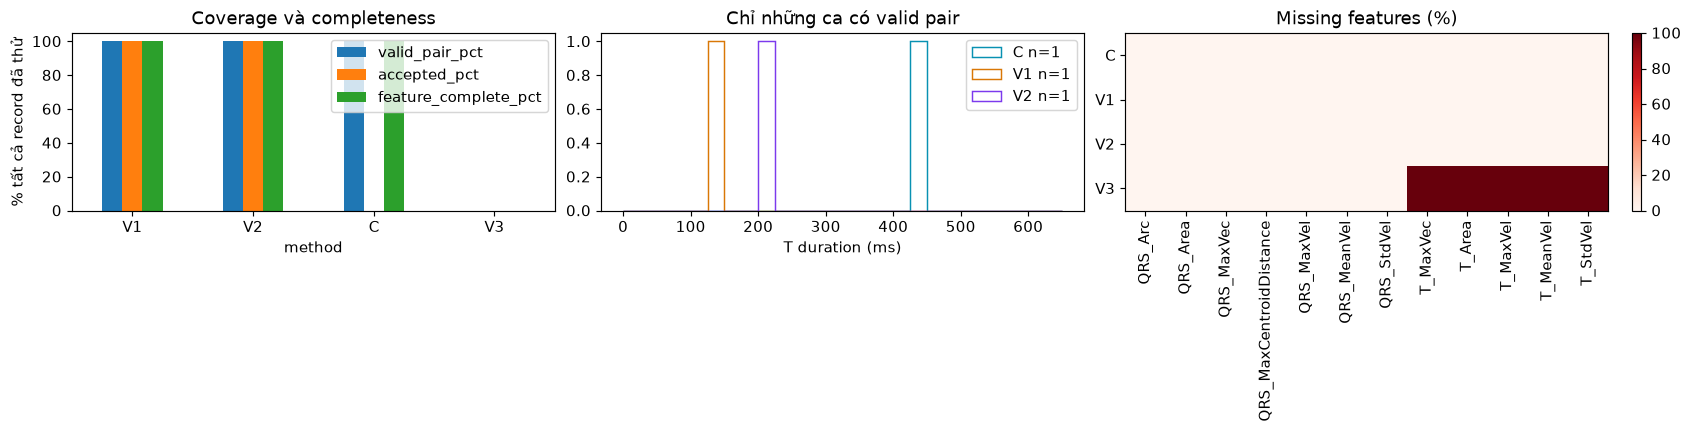

,method,split,label_name,attempted,patients,valid,accepted,feature_complete
0,C,train,HC,1,1,1,0,1
1,V1,train,HC,1,1,1,1,1
2,V2,train,HC,1,1,1,1,1
3,V3,train,HC,1,1,0,0,0


,method,flag,records
0,C,Các ngưỡng PSD/persistence/quiet là heuristic ...,1
1,C,duration_review,1
2,V1,Các ngưỡng PSD/persistence/quiet là heuristic ...,1
3,V2,Các ngưỡng PSD/persistence/quiet là heuristic ...,1
4,V3,Các ngưỡng PSD/persistence/quiet là heuristic ...,1
5,V3,invalid_or_missing_T_pair,1
6,V3,no_joint_boundary_agreement,1


In [25]:
fig,ax=plt.subplots(1,3,figsize=(16,4),layout="constrained")
cx_coverage.set_index("method")[["valid_pair_pct","accepted_pct","feature_complete_pct"]].plot.bar(ax=ax[0],rot=0)
ax[0].set(ylabel="% tất cả record đã thử",ylim=(0,105),title="Coverage và completeness")
for m,g in cx_eval.groupby("method"):
    x=pd.to_numeric(g.get("duration_ms",pd.Series(dtype=float)),errors="coerce").dropna()
    if len(x): ax[1].hist(x,bins=np.arange(0,651,25),histtype="step",label=f"{m} n={len(x)}",color=CX_COLORS[m])
ax[1].set(xlabel="T duration (ms)",title="Chỉ những ca có valid pair")
if ax[1].has_data(): ax[1].legend()
missing=cx_eval.groupby("method")[FEATURE_NAMES].agg(lambda s:100*s.isna().mean())
im=ax[2].imshow(missing.to_numpy(),aspect="auto",vmin=0,vmax=100,cmap="Reds")
ax[2].set(yticks=range(len(missing)),yticklabels=missing.index,xticks=range(len(FEATURE_NAMES)),
          xticklabels=FEATURE_NAMES,title="Missing features (%)")
ax[2].tick_params(axis="x",rotation=90);fig.colorbar(im,ax=ax[2])
cx_show(fig,"coverage_missingness")
display(cx_eval.groupby(["method","split","label_name"],dropna=False).agg(
    attempted=("record_id","size"),patients=("patient_id","nunique"),valid=("valid_pair","sum"),
    accepted=("accepted","sum"),feature_complete=("feature_complete","sum")).reset_index())
cx_flags=(cx_eval.assign(flag=cx_eval["flags"].fillna("").str.split(";")).explode("flag"))
cx_flags=cx_flags[cx_flags.flag.ne("")].groupby(["method","flag"]).size().rename("records").reset_index()
display(cx_flags.sort_values(["method","records"],ascending=[True,False]))
CX_RESULTS["flags"]=cx_flags

### Chênh lệch từng cặp, Bland–Altman và overlap

Ở mọi cột delta, dấu dương nghĩa là method bên phải đặt mốc muộn hơn method bên trái. Ví dụ V1→V3 onset +20 ms là onset V3 muộn hơn 20 ms. Median absolute delta là khoảng cách giữa hai phương pháp, không phải sai số với nhãn thật. Với một record không tính được SD/limits đáng tin; đợi cohort.

Các feature QRS phải giữ nguyên giữa V1/V2/C/V3 vì chưa thay QRS hay preprocessing. Bảng pairwise đầy đủ còn có các cột chênh lệch từng feature, relative delta và Spearman trên paired valid records.

**Nếu hình ít điểm hoặc trống:** xem `valid_pairs` trong bảng cell 51 và `valid_pair/flags` ở cell 47–49. Một demo chỉ có 1 điểm cho mỗi cặp hợp lệ; V3 unresolved sẽ không có điểm cho các cặp chứa V3. Hình mới vẽ tất cả cặp có dữ liệu, kèm tên và số điểm; vùng không có dữ liệu được ghi rõ, không thay NaN bằng 0.

,left,right,attempted_pairs,valid_pairs,both_accepted,median_iou,median_dice,t_on_ms_median_abs,t_off_ms_median_abs,duration_median_abs_difference_ms
0,V1,V2,1,1,1,0.719807,0.837079,34.0,24.0,58.0
1,V1,C,1,1,0,0.347319,0.515571,88.0,192.0,280.0
2,V1,V3,1,0,0,NaN,NaN,NaN,NaN,NaN
3,V2,C,1,1,0,0.482517,0.650943,54.0,168.0,222.0
4,V2,V3,1,0,0,NaN,NaN,NaN,NaN,NaN
5,C,V3,1,0,0,NaN,NaN,NaN,NaN,NaN


,left,right,attempted_pairs,valid_pairs,both_accepted,t_on_ms_bias,t_on_ms_median_signed,t_on_ms_median_abs,t_on_ms_p90_abs,t_on_ms_sd,t_on_ms_loa_low,t_on_ms_loa_high,t_on_ms_within_10ms_pct,t_on_ms_within_20ms_pct,t_on_ms_within_25ms_pct,t_on_ms_within_40ms_pct,t_on_ms_within_50ms_pct,t_off_ms_bias,t_off_ms_median_signed,t_off_ms_median_abs,...,T_MaxVec_paired_n,T_MaxVec_median_abs_delta,T_MaxVec_median_relative_delta_pct,T_MaxVec_spearman,T_Area_paired_n,T_Area_median_abs_delta,T_Area_median_relative_delta_pct,T_Area_spearman,T_MaxVel_paired_n,T_MaxVel_median_abs_delta,T_MaxVel_median_relative_delta_pct,T_MaxVel_spearman,T_MeanVel_paired_n,T_MeanVel_median_abs_delta,T_MeanVel_median_relative_delta_pct,T_MeanVel_spearman,T_StdVel_paired_n,T_StdVel_median_abs_delta,T_StdVel_median_relative_delta_pct,T_StdVel_spearman
0,V1,V2,1,1,1,-34.0,-34.0,34.0,34.0,NaN,NaN,NaN,0.0,0.0,0.0,100.0,100.0,24.0,24.0,24.0,...,1.0,0.0,0.0,NaN,1.0,0.003270,11.916640,NaN,1.0,0.0,0.0,NaN,1.0,0.914059,-16.250790,NaN,1.0,0.195911,8.751556,NaN
1,V1,C,1,1,0,-88.0,-88.0,88.0,88.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,192.0,192.0,192.0,...,1.0,0.0,0.0,NaN,1.0,0.005232,19.067748,NaN,1.0,0.0,0.0,NaN,1.0,2.813422,-50.018990,NaN,1.0,0.280408,12.526141,NaN
2,V1,V3,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,V2,C,1,1,0,-54.0,-54.0,54.0,54.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,168.0,168.0,168.0,...,1.0,0.0,0.0,NaN,1.0,0.001962,6.389674,NaN,1.0,0.0,0.0,NaN,1.0,1.899362,-40.320619,NaN,1.0,0.084497,3.470833,NaN
4,V2,V3,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,C,V3,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Record đang đánh giá: 1 | dòng so sánh cặp hợp lệ: 3
Mỗi điểm là một record của một cặp phương pháp; một record demo chỉ tạo một điểm/cặp.


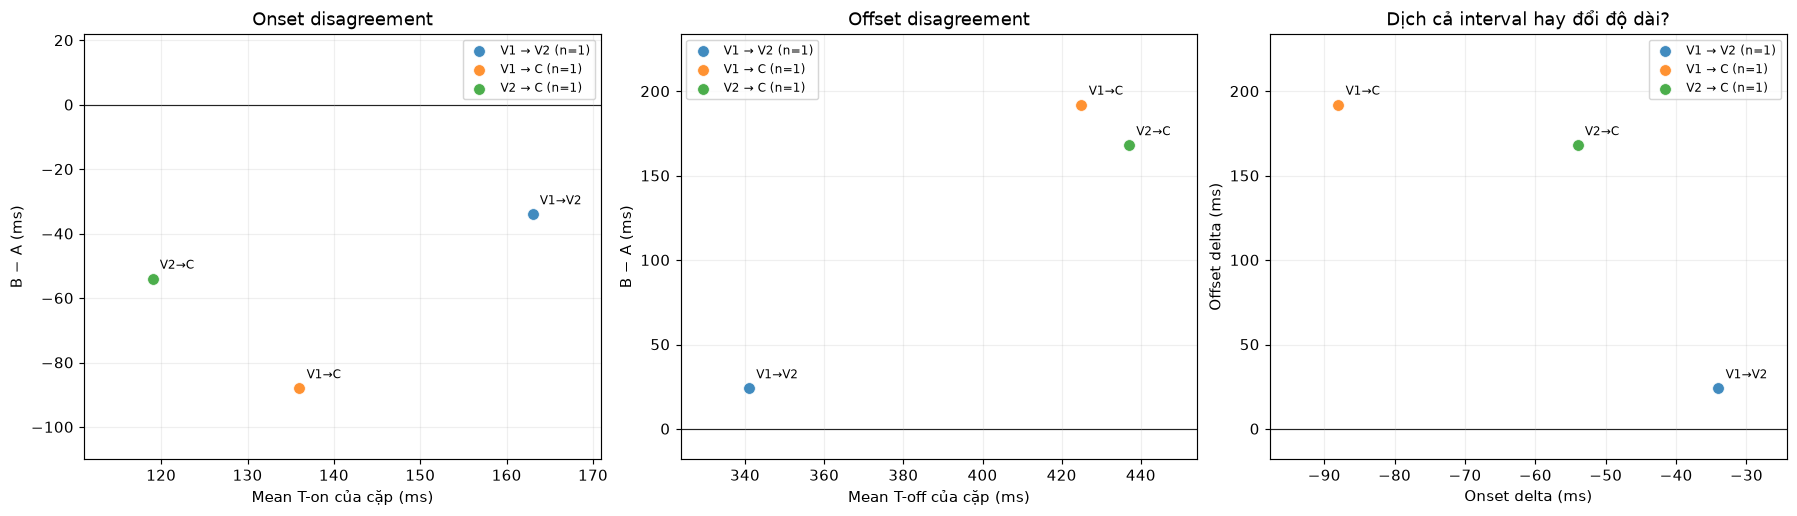

Các cặp không có điểm để vẽ (không coi là chênh lệch bằng 0):


,left,right,attempted_pairs,valid_pairs
2,V1,V3,1,0
4,V2,V3,1,0
5,C,V3,1,0


,method,metric,estimate,low,high,patients,note
0,C,accepted_rate,0.0,NaN,NaN,1,too_few_patients_for_CI
1,V1,accepted_rate,1.0,NaN,NaN,1,too_few_patients_for_CI
2,V2,accepted_rate,1.0,NaN,NaN,1,too_few_patients_for_CI
3,V3,accepted_rate,0.0,NaN,NaN,1,too_few_patients_for_CI


In [26]:
# Visual revision 2: vẽ mọi cặp có dữ liệu; không để khung trống.
cx_pairs,cx_pair_details=cx_pairwise(cx_eval)
base_cols=["left","right","attempted_pairs","valid_pairs","both_accepted","median_iou","median_dice",
           "t_on_ms_median_abs","t_off_ms_median_abs","duration_median_abs_difference_ms"]
display(cx_pairs.reindex(columns=base_cols))
display(cx_pairs)
print("Record đang đánh giá:",cx_eval.record_id.nunique(),
      "| dòng so sánh cặp hợp lệ:",len(cx_pair_details))
print("Mỗi điểm là một record của một cặp phương pháp; một record demo chỉ tạo một điểm/cặp.")
fig,axes=plt.subplots(1,3,figsize=(17,4.8),layout="constrained")
if not cx_pair_details.empty:
    for j,((a,b),g) in enumerate(cx_pair_details.groupby(["left","right"],sort=False)):
        color=plt.get_cmap("tab10")(j%10)
        label=f"{a} → {b} (n={len(g)})"
        for ax,x,y in ((axes[0],g.on_mean_ms,g.on_delta_ms),
                       (axes[1],g.off_mean_ms,g.off_delta_ms),
                       (axes[2],g.on_delta_ms,g.off_delta_ms)):
            ax.scatter(x,y,s=65,alpha=.85,color=color,label=label,
                       edgecolors="white",linewidths=.6,zorder=5)
            if len(g)==1:
                ax.annotate(a+"→"+b,(float(x.iloc[0]),float(y.iloc[0])),
                            xytext=(5,7),textcoords="offset points",fontsize=8)
    for ax in axes:
        ax.margins(x=.18,y=.25)
        ax.legend(fontsize=8,loc="best")
else:
    for ax in axes:
        ax.text(.5,.5,"Không có record mà cả hai phương pháp\ncùng trả được cặp biên T hợp lệ.\nXem valid_pairs/flags ở cell 47–49.",
                ha="center",va="center",transform=ax.transAxes,fontsize=10)
for ax in axes:
    ax.axhline(0,color="black",lw=.8,zorder=1)
    ax.grid(alpha=.2)
axes[0].set(xlabel="Mean T-on của cặp (ms)",ylabel="B − A (ms)",title="Onset disagreement")
axes[1].set(xlabel="Mean T-off của cặp (ms)",ylabel="B − A (ms)",title="Offset disagreement")
axes[2].set(xlabel="Onset delta (ms)",ylabel="Offset delta (ms)",title="Dịch cả interval hay đổi độ dài?")
cx_show(fig,"pairwise_boundary_deltas")
if not cx_pairs.empty:
    cx_unpaired=cx_pairs.loc[cx_pairs.valid_pairs.eq(0),["left","right","attempted_pairs","valid_pairs"]]
    if not cx_unpaired.empty:
        print("Các cặp không có điểm để vẽ (không coi là chênh lệch bằng 0):")
        display(cx_unpaired)
for q in [f for f in FEATURE_NAMES if f.startswith("QRS_")]:
    counts=cx_eval.pivot(index="record_id",columns="method",values=q).nunique(axis=1,dropna=True)
    assert counts.le(1).all(), "QRS feature thay đổi ngoài thiết kế: "+q
cx_ci=cx_patient_ci(cx_eval)
display(cx_ci)
CX_RESULTS.update(pairwise_summary=cx_pairs,pairwise_details=cx_pair_details,patient_bootstrap_ci=cx_ci)


### Cùng nhiễu, cùng seeds: V1/V2/C/V3 có đổi quyết định không?

Noise thêm vào **median beat**, giữ nguyên anchors/RR/PQ/QRS detector raw; vì vậy đây là stability của tầng delineation. Scale noise = 0.5/1/2% robust scale XYZ, không phải SNR sinh lý đã biết. Báo cáo cả lần mất biên; delta chỉ tính khi trước và sau đều valid. Một phương pháp luôn thất bại không được xem là ổn định vì delta NaN.

Option bootstrap lấy mẫu lại các beat đã giữ rồi tạo median mới kiểm tra thêm độ phụ thuộc vào beat selection. Nó chưa chạy lại toàn bộ raw preprocessing và không đại diện biến thiên giữa bệnh nhân.

**Cách xem hình:** hai ô đầu là jitter có điều kiện trên những lần cả trước/sau nhiễu đều có biên hợp lệ. Ô thứ ba cho biết bao nhiêu % lần đủ điều kiện tính jitter. Đường ở 0 ms nghĩa là có đo và mốc không đổi; thiếu đường/NaN nghĩa là thiếu cặp đo, không phải thuật toán hoàn hảo.

,method,level,seed,sigma_mV,base_valid,perturbed_valid,accepted,native_status,status_changed,on_delta_ms,off_delta_ms,abs_on_delta_ms,abs_off_delta_ms
0,V1,0.005,0,0.000209,True,True,True,detected,False,0.0,0.0,0.0,0.0
1,V2,0.005,0,0.000209,True,True,True,detected,False,0.0,0.0,0.0,0.0
2,C,0.005,0,0.000209,True,True,False,detected,False,0.0,0.0,0.0,0.0
3,V3,0.005,0,0.000209,False,False,False,unresolved,False,NaN,NaN,NaN,NaN
4,V1,0.005,1,0.000209,True,True,True,detected,False,0.0,0.0,0.0,0.0
5,V2,0.005,1,0.000209,True,True,True,detected,False,0.0,0.0,0.0,0.0
6,C,0.005,1,0.000209,True,True,False,detected,False,0.0,-1.0,0.0,1.0
7,V3,0.005,1,0.000209,False,False,False,unresolved,False,NaN,NaN,NaN,NaN
8,V1,0.005,2,0.000209,True,True,True,detected,False,0.0,1.0,0.0,1.0
9,V2,0.005,2,0.000209,True,True,True,detected,False,0.0,0.0,0.0,0.0


,method,level,repetitions,base_valid,retained_valid,accepted,status_flip_rate,paired_n,on_median_abs_ms,off_median_abs_ms,on_p90_abs_ms,off_p90_abs_ms,paired_pct
0,C,0.005,5,5,5,0,0.0,5,0.0,1.0,0.0,1.0,100.0
1,C,0.010,5,5,5,0,0.0,5,1.0,1.0,1.0,1.0,100.0
2,C,0.020,5,5,5,0,0.0,5,1.0,2.0,1.6,3.0,100.0
3,V1,0.005,5,5,5,5,0.0,5,0.0,0.0,0.0,0.6,100.0
4,V1,0.010,5,5,5,5,0.0,5,0.0,0.0,0.0,0.6,100.0
5,V1,0.020,5,5,5,5,0.0,5,0.0,0.0,0.6,0.6,100.0
6,V2,0.005,5,5,5,5,0.0,5,0.0,0.0,0.0,0.0,100.0
7,V2,0.010,5,5,5,5,0.0,5,0.0,0.0,0.0,0.0,100.0
8,V2,0.020,5,5,5,5,0.0,5,0.0,0.0,0.6,0.0,100.0
9,V3,0.005,5,0,0,0,0.0,0,NaN,NaN,NaN,NaN,0.0


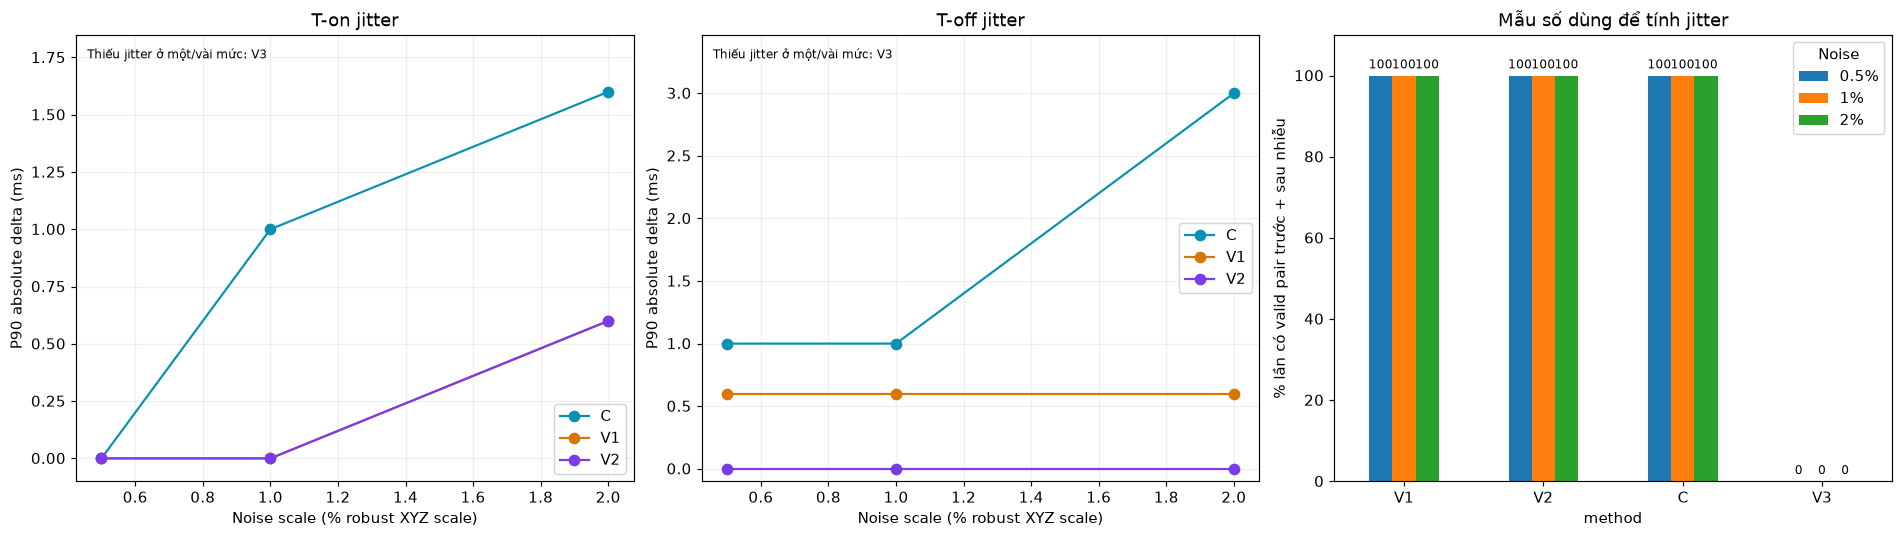

Jitter = 0: có cặp đo và mốc không đổi. NaN/không có đường: thiếu cặp đo; xem paired_n.


In [27]:
cx_stability = cx_perturb(cx_demo,cx_demo_results) if CX_RUN_STABILITY else pd.DataFrame()
cx_beat_bootstrap = cx_bootstrap(cx_demo,cx_demo_results) if CX_RUN_BOOTSTRAP else pd.DataFrame()
if not cx_stability.empty:
    for column in ("on_delta_ms","off_delta_ms"):
        cx_stability[column]=pd.to_numeric(cx_stability[column],errors="coerce")
    cx_stability["abs_on_delta_ms"]=cx_stability.on_delta_ms.abs()
    cx_stability["abs_off_delta_ms"]=cx_stability.off_delta_ms.abs()
    display(cx_stability)
    stability_summary=cx_stability.groupby(["method","level"]).agg(
        repetitions=("seed","size"),base_valid=("base_valid","sum"),retained_valid=("perturbed_valid","sum"),
        accepted=("accepted","sum"),status_flip_rate=("status_changed","mean"),
        paired_n=("on_delta_ms","count"),on_median_abs_ms=("abs_on_delta_ms","median"),
        off_median_abs_ms=("abs_off_delta_ms","median"),on_p90_abs_ms=("abs_on_delta_ms",lambda s:s.quantile(.9)),
        off_p90_abs_ms=("abs_off_delta_ms",lambda s:s.quantile(.9))).reset_index()
    stability_summary["paired_pct"]=100*stability_summary.paired_n/stability_summary.repetitions
    display(stability_summary)
    fig,axes=plt.subplots(1,3,figsize=(18,5),layout="constrained")
    for ax,metric,title in ((axes[0],"on_p90_abs_ms","T-on jitter"),
                            (axes[1],"off_p90_abs_ms","T-off jitter")):
        omitted=[]
        plotted=0
        for m,g in stability_summary.groupby("method",sort=False):
            good=np.isfinite(pd.to_numeric(g[metric],errors="coerce"))
            if good.any():
                ax.plot(g.loc[good,"level"]*100,g.loc[good,metric],"o-",
                        color=CX_COLORS[m],label=m,markersize=7,zorder=5)
                plotted+=1
            if not good.all(): omitted.append(m)
        if plotted:
            ax.legend()
            ax.set_ylim(bottom=-.1,top=max(1.,ax.get_ylim()[1]*1.1))
        else:
            ax.text(.5,.5,"Không có cặp biên hợp lệ trước và sau nhiễu.\nJitter không xác định (NaN), không phải 0.",
                    ha="center",va="center",transform=ax.transAxes)
        if omitted:
            ax.text(.02,.97,"Thiếu jitter ở một/vài mức: "+", ".join(omitted),
                    va="top",transform=ax.transAxes,fontsize=8)
        ax.set(xlabel="Noise scale (% robust XYZ scale)",ylabel="P90 absolute delta (ms)",title=title)
        ax.grid(alpha=.2)
    pairing=stability_summary.pivot(index="method",columns="level",values="paired_pct").reindex(CX_METHODS)
    pairing.columns=[f"{100*float(v):g}%" for v in pairing.columns]
    pairing.plot.bar(ax=axes[2],rot=0)
    axes[2].set(ylim=(0,110),ylabel="% lần có valid pair trước + sau nhiễu",
                title="Mẫu số dùng để tính jitter")
    for container in axes[2].containers:
        axes[2].bar_label(container,fmt="%.0f",fontsize=8,padding=3)
    axes[2].legend(title="Noise")
    cx_show(fig,"delineation_stability")
    print("Jitter = 0: có cặp đo và mốc không đổi. NaN/không có đường: thiếu cặp đo; xem paired_n.")
    CX_RESULTS["stability_summary"]=stability_summary
else: print("Stability đang tắt hoặc không có lần thử. Kiểm tra CX_RUN_STABILITY, CX_NOISE_LEVELS, CX_SEEDS.")
if not cx_beat_bootstrap.empty: display(cx_beat_bootstrap)
CX_RESULTS.update(stability=cx_stability,beat_bootstrap=cx_beat_bootstrap)


### Dịch biên ±5/10/20 ms và đo lại features

Chạy cùng tập shift cho mọi method có valid interval. Có 3 kiểu: chỉ onset, chỉ offset, hoặc dịch cả interval. Mỗi ca không còn đúng thứ tự hoặc loại peak ra ngoài đều giữ dòng invalid và NaN; không âm thầm clip vào mảng. Relative change dùng |baseline feature| ở mẫu số; baseline gần 0 được ghi NaN để tránh tỷ lệ khổng lồ vô nghĩa.

Heatmap chỉ hiển thị median |relative change| của các scenario valid, còn bảng invalid cho biết mẫu đã mất. Các feature có đơn vị khác nhau được xem riêng; không cộng Area, MaxVec và Velocity thành một thang tổng.

,method,scenario,on_shift_ms,off_shift_ms,represented_on_shift_ms,represented_off_shift_ms,valid,reason,feature,baseline,value,delta,abs_delta,relative_delta_pct
0,V1,baseline,0,0,0.0,0.0,True,,QRS_Arc,5.892343,5.892343,0.000000,0.000000,0.000000
1,V1,baseline,0,0,0.0,0.0,True,,QRS_Area,2.076441,2.076441,0.000000,0.000000,0.000000
2,V1,baseline,0,0,0.0,0.0,True,,QRS_MaxVec,2.391030,2.391030,0.000000,0.000000,0.000000
3,V1,baseline,0,0,0.0,0.0,True,,QRS_MaxCentroidDistance,1.673200,1.673200,0.000000,0.000000,0.000000
4,V1,baseline,0,0,0.0,0.0,True,,QRS_MaxVel,170.154227,170.154227,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
679,C,translate,20,20,20.0,20.0,True,,T_MaxVec,0.552880,0.552880,0.000000,0.000000,0.000000
680,C,translate,20,20,20.0,20.0,True,,T_Area,0.032669,0.032598,-0.000071,0.000071,-0.216471
681,C,translate,20,20,20.0,20.0,True,,T_MaxVel,11.059858,11.059858,0.000000,0.000000,0.000000
682,C,translate,20,20,20.0,20.0,True,,T_MeanVel,2.811285,2.802253,-0.009033,0.009033,-0.321305


,method,valid,scenarios
0,C,True,19
1,V1,True,19
2,V2,True,19


feature,QRS_Arc,QRS_Area,QRS_MaxVec,QRS_MaxCentroidDistance,QRS_MaxVel,QRS_MeanVel,QRS_StdVel,T_MaxVec,T_Area,T_MaxVel,T_MeanVel,T_StdVel
method,,,,,,,,,,,,
V1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.641566,0.0,2.182161,2.733526
V2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.675376,0.0,2.142565,1.478447
C,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.226672,0.0,0.854594,0.319403
V3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


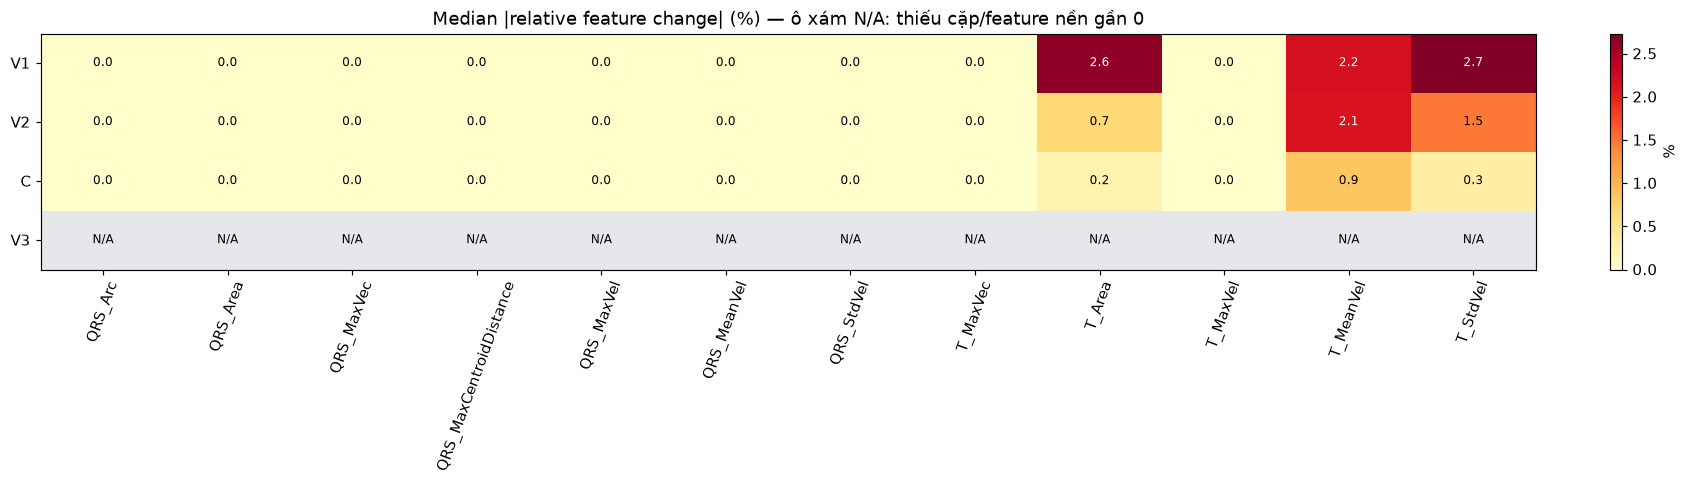

In [28]:
cx_sens=cx_sensitivity(cx_demo,cx_demo_results) if CX_RUN_SENSITIVITY else pd.DataFrame()
if not cx_sens.empty:
    display(cx_sens)
    display(cx_sens[["method","scenario","on_shift_ms","off_shift_ms","valid","reason"]].drop_duplicates()
            .groupby(["method","valid"]).size().rename("scenarios").reset_index())
    vis=cx_sens[(cx_sens.scenario!="baseline") & cx_sens.valid].copy()
    vis["abs_relative_pct"]=vis.relative_delta_pct.abs()
    grid=vis.pivot_table(index="method",columns="feature",values="abs_relative_pct",aggfunc="median")
    grid=grid.reindex(index=CX_METHODS,columns=FEATURE_NAMES)
    display(grid)
    fig,ax=plt.subplots(figsize=(16,4.5),layout="constrained")
    values=grid.to_numpy(dtype=float)
    cmap=plt.get_cmap("YlOrRd").copy();cmap.set_bad("#e5e7eb")
    finite=values[np.isfinite(values)]
    vmax=max(float(finite.max()),1e-6) if len(finite) else 1.
    im=ax.imshow(np.ma.masked_invalid(values),aspect="auto",cmap=cmap,vmin=0,vmax=vmax)
    for (row,col),value in np.ndenumerate(values):
        ax.text(col,row,f"{value:.1f}" if np.isfinite(value) else "N/A",
                ha="center",va="center",fontsize=8,
                color="white" if np.isfinite(value) and value>.65*vmax else "black")
    ax.set(yticks=range(len(grid)),yticklabels=grid.index,xticks=range(len(grid.columns)),xticklabels=grid.columns,
           title="Median |relative feature change| (%) — ô xám N/A: thiếu cặp/feature nền gần 0")
    ax.tick_params(axis="x",rotation=70);fig.colorbar(im,ax=ax,label="%")
    cx_show(fig,"feature_boundary_sensitivity")
else:
    print("Không có sensitivity: đang tắt hoặc không method nào có valid T.")
    display(pd.DataFrame([dict(method=m,valid_T=cx_order(cx_demo,b),status=b["status"],
        flags=";".join(b.get("flags",[]))) for m,b in cx_demo_results.items()]))
CX_RESULTS["feature_sensitivity"]=cx_sens


### Các option consensus và ablation

So sánh complete-link tolerance 10/25/40 ms × [2/3 phiếu, 3/3 phiếu, V1+V2, V2+C, V1+C]. Cùng một nhóm phải đồng ý **cả onset và offset**. Không ghép onset từ nhóm A với offset từ nhóm B. Tolerance kiểm tra max–min, tránh hiện tượng nối chuỗi 0→20→40 ms rồi nhận cả ba ở ngưỡng 25 ms.

V1+C có tương quan vì cùng magnitude/baseline; coverage cao của cặp này không phải bằng chứng độc lập. Bảng demo giải thích tác động cấu hình; chỉ thí nghiệm lựa chọn trên train/valid, khóa cấu hình trước khi báo cáo test. Không tự chọn “option tốt nhất” theo agreement.

In [29]:
cx_option_rows=cx_options(cx_demo,cx_demo_results)
display(cx_option_rows[["option","native_status","valid_pair","accepted","t_on_ms","t_off_ms",
                        "duration_ms","votes","on_spread_ms","off_spread_ms","flags"]])
CX_RUN_COHORT_OPTIONS=False  # đắt: tải lại cùng tập selected của cohort; chọn scope train_valid
cx_sweep=pd.DataFrame()
if CX_RUN_COHORT_OPTIONS:
    if cx_selected.empty: raise ValueError("Bật CX_RUN_COHORT trước khi sweep cohort.")
    if not cx_selected.split.isin(["train","val"]).all():
        raise ValueError("Option sweep chỉ dùng train/valid; không tuning trên test.")
    cx_sweep=cx_cohort_sweep(cx_selected)
    display(cx_sweep.groupby("option").agg(attempted=("record_id","size"),
        valid=("valid_pair","sum"),accepted=("accepted","sum")))
CX_RESULTS.update(demo_options=cx_option_rows,cohort_option_sweep=cx_sweep)

,option,native_status,valid_pair,accepted,t_on_ms,t_off_ms,duration_ms,votes,on_spread_ms,off_spread_ms,flags
0,V1+V2+C | votes=2 | tol=10ms,unresolved,False,False,NaN,NaN,NaN,NaN,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
1,V1+V2+C | votes=3 | tol=10ms,unresolved,False,False,NaN,NaN,NaN,NaN,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
2,V1+V2 | votes=2 | tol=10ms,unresolved,False,False,NaN,NaN,NaN,NaN,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
3,V2+C | votes=2 | tol=10ms,unresolved,False,False,NaN,NaN,NaN,NaN,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
4,V1+C | votes=2 | tol=10ms,unresolved,False,False,NaN,NaN,NaN,NaN,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
5,V1+V2+C | votes=2 | tol=25ms,unresolved,False,False,NaN,NaN,NaN,NaN,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
6,V1+V2+C | votes=3 | tol=25ms,unresolved,False,False,NaN,NaN,NaN,NaN,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
7,V1+V2 | votes=2 | tol=25ms,unresolved,False,False,NaN,NaN,NaN,NaN,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
8,V2+C | votes=2 | tol=25ms,unresolved,False,False,NaN,NaN,NaN,NaN,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
9,V1+C | votes=2 | tol=25ms,unresolved,False,False,NaN,NaN,NaN,NaN,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...


### So sánh các feature CSV V1/V2 có sẵn và kiểm tra provenance

Các CSV trong data/features là kết quả đã xuất, giúp kiểm tra cohort và missingness mà không cần raw. Chúng không tự động là cùng lần chạy hiện tại: phiên bản code, preprocessing và median có thể khác. Bảng dưới chỉ kiểm kê, không trộn chúng vào kết quả V3. Chỉ đối chiếu giá trị từng record khi median/cấu hình được kiểm chứng cùng nguồn.

Nếu outputs/vcg_full_evaluation/artifacts đã được tạo bởi V1, có thể kiểm tra chính median của demo với artifact V1. Hash dưới đây dùng bytes float64 của median; khác với SHA256 của toàn file NPZ. Không so hai loại hash với nhau.

**Đọc bảng provenance:** `status=verified` nghĩa là đã đọc và kiểm tra artifact; chỉ `same_median=True` mới cho phép so trực tiếp trên cùng median. `artifact_error` hiển thị lỗi đọc/kiểm tra, không được hiểu là đạt. JSON artifact được đọc bằng UTF-8 trên Windows.

In [30]:
tracked=[]
for version in ("v1","v2"):
    for split in ("train","valid","test"):
        path=CX_ROOT/"data/features"/version/(split+"_features.csv")
        if path.is_file():
            f=pd.read_csv(path)
            tracked.append(dict(version=version,split=split,rows=len(f),patients=f.patient_id.nunique(),
                complete_12=int(f[FEATURE_NAMES].notna().all(axis=1).sum()),csv_sha256=cx_file_hash(path)))
cx_tracked=pd.DataFrame(tracked)
display(cx_tracked)
artifact_root=CX_ROOT/"outputs/vcg_full_evaluation/artifacts"
stem=CX_DEMO_ID.replace("/","_")
if (artifact_root/(stem+".json")).is_file() and (artifact_root/(stem+".npz")).is_file():
    # Reload để kernel đang mở cũng nhận bản reader UTF-8 vừa sửa.
    import importlib
    from scripts import vcg_reference_metrics as cx_reference_metrics
    cx_reference_metrics=importlib.reload(cx_reference_metrics)
    try:
        saved=cx_reference_metrics.load_median(artifact_root,CX_DEMO_ID)
        current=cx_demo["rep"]
        same=(saved["xyz"] is not None and saved["xyz"].shape==current["xyz"].shape and
              saved["fs"]==cx_demo["fs"] and saved["anchor"]==current["anchor"] and
              np.allclose(saved["xyz"],current["xyz"],rtol=0,atol=1e-10))
        cx_artifact_check=pd.DataFrame([dict(record_id=CX_DEMO_ID,status="verified",
            same_median=same,current_signal_hash=cx_signal_hash(current["xyz"]),
            saved_signal_hash=cx_signal_hash(saved["xyz"]) if saved["xyz"] is not None else None,
            note="Hash cùng mảng XYZ; không so hash mảng với hash file NPZ.")])
        if not same: print("Artifact V1 khác median: chỉ so các method vừa chạy trên cùng median hiện tại.")
    except (OSError, ValueError, KeyError) as exc:
        cx_artifact_check=pd.DataFrame([dict(record_id=CX_DEMO_ID,status="artifact_error",
            same_median=None,error=type(exc).__name__+": "+str(exc))])
        print("Không xác minh được artifact cũ; xem lỗi dưới đây. Không coi provenance là đạt.")
    display(cx_artifact_check)
    CX_RESULTS["artifact_provenance"]=cx_artifact_check
else: print("Chưa có artifact V1; evaluator vẫn chạy độc lập từ raw, không tự chạy notebook khác.")
CX_RESULTS["tracked_feature_inventory"]=cx_tracked

,version,split,rows,patients,complete_12,csv_sha256
0,v1,train,263,120,259,641bbfe2527e8fb946b552b552a349463b3523705b263c...
1,v1,valid,70,30,67,c4becc594f5a433c24ec95186ce4b20c6ba4ae852327d1...
2,v1,test,115,50,115,49560bc1f5f2f87bc5afb236c5e046bade9a883a1e0f5a...
3,v2,train,263,120,176,637da1b991220708b4ec4472a5348cd9e4a267dd0e30ba...
4,v2,valid,70,30,46,03df94faeb10af545220710b94cff8b05a9cf836343872...
5,v2,test,115,50,90,c6948355640a76c94199988f73ca3dfc3cde71353a2517...


,record_id,status,same_median,current_signal_hash,saved_signal_hash,note
0,patient104/s0306lre,verified,True,93836b8abbee1af5351f737e3dc3655efb11d1fc2bc318...,93836b8abbee1af5351f737e3dc3655efb11d1fc2bc318...,Hash cùng mảng XYZ; không so hash mảng với has...


### Option downstream MI/HC: cùng split, cùng model, cùng feature policy

MI/HC có nhãn nên có thể tính các chỉ số phân loại, nhưng kết quả này chỉ đo tác vụ chẩn đoán, không xác nhận độ đúng biên T. Bật CX_RUN_ML và chạy cohort đầy đủ với CX_SCOPE="all", CX_COHORT_LIMIT=None. Cấu hình và method được khóa trước khi xem test.

Cùng 12 feature, Logistic Regression class_weight=balanced, median imputer và scaler **fit trên train**. Không đưa ID/diagnosis/QC vào predictor. Mọi method dùng cùng danh sách record theo split, cả ca thiếu feature; thống kê missingness riêng, không lọc mỗi method thành cohort khác. QRS-only là baseline để kiểm tra lợi ích thực sự của phần T. Nếu cả một cột train thiếu hết thì bỏ model có giải thích thay vì tự bịa giá trị.

Các metric: confusion counts, sensitivity, specificity, precision, F1, balanced accuracy, accuracy, MCC, ROC-AUC, AP/PR, Brier, log-loss; kèm patient-level mean-probability cùng threshold 0.5. AP phụ thuộc prevalence; calibration phản ánh pipeline hiện tại và không được điều chỉnh theo test.

In [31]:
cx_ml_metrics=pd.DataFrame(); cx_ml_predictions=pd.DataFrame()
CX_ML_FEATURE_POLICY="valid"  # valid: candidate hợp lệ; accepted: mask T nếu chưa qua screening
if CX_RUN_ML:
    if not CX_RUN_COHORT or CX_SCOPE!="all" or CX_COHORT_LIMIT is not None:
        raise ValueError("ML cần full cohort: CX_RUN_COHORT=True, CX_SCOPE='all', CX_COHORT_LIMIT=None.")
    from sklearn.pipeline import make_pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import (confusion_matrix,accuracy_score,balanced_accuracy_score,
        precision_score,recall_score,f1_score,matthews_corrcoef,roc_auc_score,
        average_precision_score,brier_score_loss,log_loss,roc_curve,precision_recall_curve)
    metric_rows=[]; pred_rows=[]; ml_skipped=[]
    model_names=("QRS_only","V1","V2","V3")
    for method in model_names:
        source="V1" if method=="QRS_only" else method
        data=cx_cohort[cx_cohort.method.eq(source)].copy()
        if set(data.record_id)!=set(CX_SPLIT.record_id): raise ValueError("Cohort không phủ đúng manifest.")
        feats=[f for f in FEATURE_NAMES if f.startswith("QRS_")] if method=="QRS_only" else FEATURE_NAMES
        if method!="QRS_only" and CX_ML_FEATURE_POLICY=="accepted":
            data.loc[~data.accepted,[f for f in FEATURE_NAMES if f.startswith("T_")]]=np.nan
        elif CX_ML_FEATURE_POLICY not in ("valid","accepted"): raise ValueError("Unknown ML feature policy.")
        train=data[data.split.eq("train")]
        if train.label_name.nunique()!=2 or train[feats].isna().all().any():
            ml_skipped.append(dict(method=method,reason="train lacks two classes or all-missing feature column"));continue
        model=make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),
            LogisticRegression(max_iter=3000,class_weight="balanced",random_state=2026))
        model.fit(train[feats],train.label_name.eq("MI").astype(int))
        for split in ("val","test"):
            part=data[data.split.eq(split)]
            if part.empty: continue
            prob=model.predict_proba(part[feats])[:,list(model.classes_).index(1)]
            for rid,pid,label,p in zip(part.record_id,part.patient_id,part.label_name,prob):
                pred_rows.append(dict(method=method,split=split,record_id=rid,patient_id=pid,
                                      y=int(label=="MI"),probability_mi=float(p)))
    cx_ml_predictions=pd.DataFrame(pred_rows)
    display(pd.DataFrame(ml_skipped))
    def classification_row(method,split,unit,g):
        y=g.y.to_numpy(); prob=g.probability_mi.to_numpy(); pred=(prob>=.5).astype(int)
        tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
        return dict(method=method,split=split,unit=unit,n=len(y),prevalence=float(y.mean()),
            tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),accuracy=accuracy_score(y,pred),
            balanced_accuracy=balanced_accuracy_score(y,pred),sensitivity=tp/(tp+fn) if tp+fn else np.nan,
            specificity=tn/(tn+fp) if tn+fp else np.nan,precision=precision_score(y,pred,zero_division=0),
            f1=f1_score(y,pred,zero_division=0),mcc=matthews_corrcoef(y,pred),
            roc_auc=roc_auc_score(y,prob) if len(np.unique(y))==2 else np.nan,
            average_precision=average_precision_score(y,prob) if len(np.unique(y))==2 else np.nan,
            brier=brier_score_loss(y,prob),log_loss=log_loss(y,prob,labels=[0,1]))
    if not cx_ml_predictions.empty:
        for (m,s),g in cx_ml_predictions.groupby(["method","split"]):
            metric_rows.append(classification_row(m,s,"record",g))
            assert g.groupby("patient_id").y.nunique().max()==1
            patient=g.groupby("patient_id").agg(y=("y","first"),probability_mi=("probability_mi","mean")).reset_index()
            metric_rows.append(classification_row(m,s,"patient_mean_probability",patient))
        cx_ml_metrics=pd.DataFrame(metric_rows)
        display(cx_ml_metrics)
        fig,axes=plt.subplots(1,3,figsize=(16,4),layout="constrained")
        for m,g in cx_ml_predictions[cx_ml_predictions.split.eq("test")].groupby("method"):
            if g.y.nunique()<2: continue
            fpr,tpr,_=roc_curve(g.y,g.probability_mi);precision,recall,_=precision_recall_curve(g.y,g.probability_mi)
            axes[0].plot(fpr,tpr,label=m);axes[1].plot(recall,precision,label=m)
            bins=pd.cut(g.probability_mi,np.linspace(0,1,6),include_lowest=True)
            calibration=g.groupby(bins,observed=True).agg(mean_probability=("probability_mi","mean"),
                observed_MI=("y","mean"),n=("y","size"))
            axes[2].plot(calibration.mean_probability,calibration.observed_MI,"o-",label=m)
        axes[0].plot([0,1],[0,1],"k:");axes[2].plot([0,1],[0,1],"k:")
        axes[0].set(xlabel="False-positive rate",ylabel="Sensitivity",title="Test ROC")
        axes[1].set(xlabel="Recall MI",ylabel="Precision MI",title="Test precision–recall")
        axes[2].set(xlabel="Mean predicted p(MI)",ylabel="Observed MI fraction",title="Calibration (5 bins)")
        for ax in axes:
            ax.grid(alpha=.2)
            if ax.has_data(): ax.legend(fontsize=8)
        cx_show(fig,"downstream_ML")
else: print("CX_RUN_ML=False; không train model hay đọc test để lựa chọn option.")
CX_RESULTS.update(ml_metrics=cx_ml_metrics,ml_predictions=cx_ml_predictions)

CX_RUN_ML=False; không train model hay đọc test để lựa chọn option.


### Export và checklist đọc kết luận

Bật CX_SAVE_REPORTS để ghi CSV + config + fingerprint, selected manifest và review queue vào outputs/vcg_shared_comparison/<notebook>/<run_tag_protocol>. Các file được ghi khi bạn chạy cell này. Đổi CX_RUN_TAG để giữ lại lần chạy cũ. Tất cả bảng candidate giữ nguyên; accepted_features riêng sẽ mask T ở ca chưa accepted, giúp tránh dùng nhầm.

Review queue ưu tiên ca mất biên, nhiều flags và pairwise delta lớn; đó là danh sách kiểm tra bằng mắt, không phải expert labels. Template reference để trống, không sao chép prediction làm ground truth.

Nếu sau này có annotation độc lập, cần cùng beat, time origin, fs, reviewer và nguồn nhãn; khi đó mới tính MAE/RMSE/bias/tolerance accuracy của boundaries hoặc Se/PPV/F1 của event matching. Hiện tại các mục này là “chưa có reference”, không gán bằng 0.

**Cách kết luận:** xem failures/coverage theo MI/HC và split → paired delta/IoU → robustness và feature sensitivity → downstream task nếu bật → xem thủ công ca bất đồng. Coverage, loop closure hoặc agreement cao không đủ để xếp hạng độ đúng T. Các cờ method khác nhau về độ bảo thủ; đọc riêng common_flags và method_flags trước khi dùng accepted rate để so sánh.

In [32]:
cx_review=cx_eval[["record_id","patient_id","method","native_status","accepted","flags"]].copy()
if not cx_pair_details.empty:
    disagreement=cx_pair_details.assign(
        max_delta_ms=cx_pair_details[["on_delta_ms","off_delta_ms"]].abs().max(axis=1)
    ).groupby("record_id").max_delta_ms.max()
    cx_review=cx_review.merge(disagreement,on="record_id",how="left")
cx_review=cx_review.sort_values(["accepted","record_id"],ascending=[True,True])
display(cx_review.head(30))
cx_reference=CX_SPLIT[CX_SPLIT.record_id.isin(cx_eval.record_id)][["record_id","patient_id","split"]].copy()
cx_reference["time_reference"]="median_relative_ms"
for name in ("qrs_on_ms","qrs_off_ms","t_on_ms","t_off_ms","reviewer","reference_source"):
    cx_reference[name]=np.nan if name.endswith("_ms") else ""
cx_reference["independent_reference"]=False
CX_RESULTS.update(review_queue=cx_review,reference_template=cx_reference)
cx_packages={p:importlib.metadata.version(p) for p in ("numpy","scipy","pandas","matplotlib","wfdb","scikit-learn")}
if CX_SAVE_REPORTS:
    CX_OUT.mkdir(parents=True,exist_ok=True)
    for name,table in CX_RESULTS.items():
        if isinstance(table,pd.DataFrame): table.to_csv(CX_OUT/(name+".csv"),index=False)
    safe_features=cx_eval.copy()
    safe_features.loc[~safe_features.accepted,[f for f in FEATURE_NAMES if f.startswith("T_")]]=np.nan
    safe_features.to_csv(CX_OUT/"accepted_features.csv",index=False)
    (CX_OUT/"config.json").write_text(json.dumps(json_safe(dict(
        **cx_config,protocol_id=CX_PROTOCOL_ID,packages=cx_packages,notebook=CX_NOTEBOOK,
        run_tag=CX_RUN_TAG,feature_policy=CX_ML_FEATURE_POLICY)),ensure_ascii=False,indent=2),encoding="utf-8")
    print("Saved:",CX_OUT)
else: print("Chỉ hiển thị. Bật CX_SAVE_REPORTS nếu muốn lưu bảng.")
print("Không có T reference: chưa tính boundary accuracy, MAE/RMSE với truth hoặc QRS event Se/PPV.")

,record_id,patient_id,method,native_status,accepted,flags,max_delta_ms
2,patient104/s0306lre,patient104,C,detected,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,192.0
3,patient104/s0306lre,patient104,V3,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,192.0
0,patient104/s0306lre,patient104,V1,detected,True,Các ngưỡng PSD/persistence/quiet là heuristic ...,192.0
1,patient104/s0306lre,patient104,V2,detected,True,Các ngưỡng PSD/persistence/quiet là heuristic ...,192.0


Chỉ hiển thị. Bật CX_SAVE_REPORTS nếu muốn lưu bảng.
Không có T reference: chưa tính boundary accuracy, MAE/RMSE với truth hoặc QRS event Se/PPV.
